# Does the order of readings inside a window matter?
**C-MAPSS FD001 and FD002 | Random Forest, XGBoost, AdaBoost | RMSE and NASA score | 5-fold CV by engine**

We build features from the last L cycles of each engine. Do they help because they capture a **trend**, or only because **averaging** removes noise?

| Condition | Features |
|---|---|
| Floor | Predict the average training RUL for everything |
| A | Current cycle only (L = 1) |
| B | mean, std, min, max, median over the last L cycles |
| C | B + slope, last-minus-first, std of differences, mean absolute difference (true order) |
| D | Same as C, but readings are shuffled inside each window first |

**Main number: C minus B.** D is a supporting check.

**How to run:** put this notebook in Kaggle with your dataset attached and click *Run All*. Set `QUICK = True` first to test everything in a couple of minutes.

*Fixes to your earlier notebook:* `df_rul_FD002` was reading `RUL_FD001.csv` (now fixed), and `pd.save_csv()` does not exist (it is `df.to_csv()`).

## 0. Settings

In [2]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

QUICK = os.environ.get("CMAPSS_QUICK", "0") == "1"      # True = small test run
DATA_DIR = os.environ.get("CMAPSS_DIR", "/kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
DATASETS = ["FD001", "FD002"]
MODELS = ["RF", "XGB", "ADA"]
WINDOWS = [5, 10, 20, 30, 50]
N_FOLDS = 5
RUL_CAP = 125            # target = min(RUL, 125)
MIN_EVAL_CYCLE = 50      # every L is scored on cycles >= 50, so rows are identical across L
EARLY_RUL, NEAR_RUL = 100, 30     # early: RUL > 100, near failure: RUL <= 30
N_CUTS = 5               # random cut-off cycles per validation engine (View 1)
D_SEEDS = 3              # shuffle repeats for condition D
TRAIN_STRIDE = 4         # use every 4th training window (windows overlap a lot; this only saves time)
N_BOOT = 1000            # engine-level bootstrap repeats
RF_TREES, XGB_TREES, ADA_TREES = 150, 300, 80

if QUICK:
    WINDOWS = [10, 30]; D_SEEDS = 1; TRAIN_STRIDE = 8; N_BOOT = 200
    RF_TREES, XGB_TREES, ADA_TREES = 30, 60, 20
print("QUICK =", QUICK, "| windows:", WINDOWS, "| data:", DATA_DIR)

def make_model(name):
    if name == "RF":
        return RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
    if name == "XGB":
        return XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=6, subsample=0.8,
                            colsample_bytree=0.8, n_jobs=-1, random_state=SEED)
    if name == "ADA":
        return AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=ADA_TREES,
                                 learning_rate=0.5, random_state=SEED)

QUICK = False | windows: [5, 10, 20, 30, 50] | data: /kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002


In [3]:
import time, numpy as np
Xt = np.random.rand(6000, 130); yt = np.random.rand(6000) * 125
for dev in ["cpu", "cuda"]:
    t = time.time()
    XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=6, subsample=0.8,
                 colsample_bytree=0.8, tree_method="hist", device=dev, random_state=SEED).fit(Xt, yt)
    print(dev, round(time.time() - t, 2), "seconds")

cpu 5.22 seconds
cuda 1.49 seconds


In [4]:
import subprocess
def gpu_available():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False
USE_GPU = gpu_available()
print("GPU available for XGBoost:", USE_GPU)

GPU available for XGBoost: True


In [5]:
def make_model(name):
    if name == "RF":
        return RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
    if name == "XGB":
        return XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=6, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist",
                            device="cuda" if USE_GPU else "cpu", n_jobs=-1, random_state=SEED)
    if name == "ADA":
        return AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=ADA_TREES,
                                 learning_rate=0.5, random_state=SEED)

## 1. Load data and check it

,dataset,train_engines,train_rows,len_min,len_median,len_max,test_engines,test_len_min,sensors_used,settings,cycles_ok
0,FD001,100,20631,128,199.0,362,100,31,19,3,True
1,FD002,260,53759,128,199.0,378,259,21,21,3,True


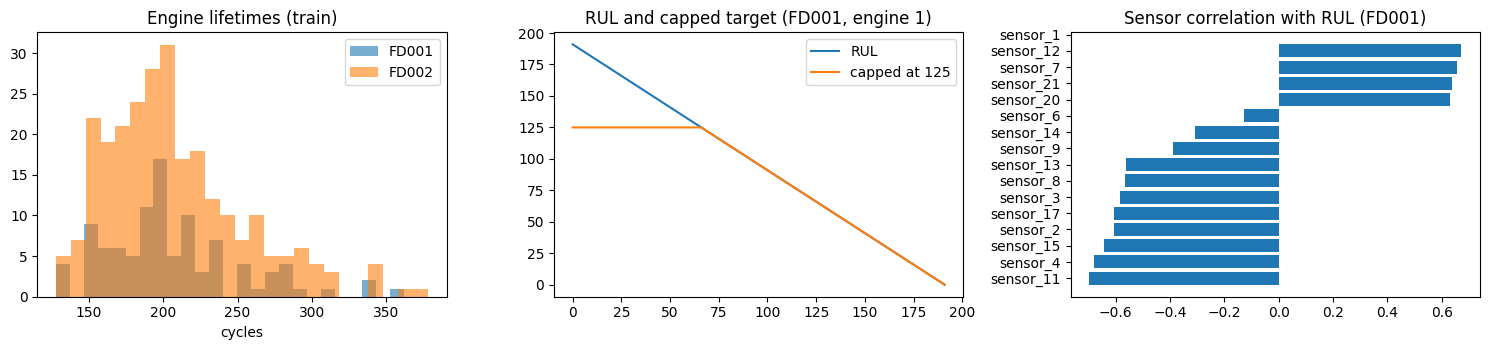

In [6]:
def add_rul(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    df["RUL"] = df.groupby("unit_id")["cycle"].transform("max") - df["cycle"]
    df["y"] = df["RUL"].clip(upper=RUL_CAP)
    return df

def read_rul(path, n_expected):
    r = pd.read_csv(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()   # works with or without a header row
    v = r.iloc[:, 0].values
    if len(v) == n_expected + 1: v = v[1:]            # a numeric-looking header row was read as data
    return v

DATA = {}
for ds in DATASETS:
    tr = add_rul(pd.read_csv(f"{DATA_DIR}/train_{ds}.csv"))
    te = pd.read_csv(f"{DATA_DIR}/test_{ds}.csv").sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    rul = read_rul(f"{DATA_DIR}/RUL_{ds}.csv", te["unit_id"].nunique())
    sensors_all = [c for c in tr.columns if c.startswith("sensor")]
    settings = [c for c in tr.columns if c not in ("unit_id", "cycle", "RUL", "y") and not c.startswith("sensor")]
    sensors = [c for c in sensors_all if tr[c].std() > 0]        # drop constant sensors
    assert len(rul) == te["unit_id"].nunique(), "RUL file length must equal number of test engines"
    DATA[ds] = dict(train=tr, test=te, rul=rul, sensors=sensors, settings=settings,
                    n_regimes=6 if ds == "FD002" else 1, groups=tr.groupby("unit_id").indices)
SETTINGS = DATA["FD001"]["settings"]

rows = []
for ds, d in DATA.items():
    tr, te = d["train"], d["test"]
    ok = tr.groupby("unit_id")["cycle"].apply(lambda s: (s.values == np.arange(1, len(s) + 1)).all()).all()
    L_tr = tr.groupby("unit_id").size(); L_te = te.groupby("unit_id").size()
    rows.append(dict(dataset=ds, train_engines=len(L_tr), train_rows=len(tr), len_min=L_tr.min(), len_median=L_tr.median(),
                     len_max=L_tr.max(), test_engines=len(L_te), test_len_min=L_te.min(),
                     sensors_used=len(d["sensors"]), settings=len(d["settings"]), cycles_ok=ok))
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for ds, c in zip(DATASETS, ["tab:blue", "tab:orange"]):
    ax[0].hist(DATA[ds]["train"].groupby("unit_id").size(), bins=25, alpha=.6, label=ds, color=c)
ax[0].set_title("Engine lifetimes (train)"); ax[0].set_xlabel("cycles"); ax[0].legend()
tr1 = DATA["FD001"]["train"]
ax[1].plot(tr1["RUL"][tr1.unit_id == 1].values, label="RUL"); ax[1].plot(tr1["y"][tr1.unit_id == 1].values, label=f"capped at {RUL_CAP}")
ax[1].set_title("RUL and capped target (FD001, engine 1)"); ax[1].legend()
corr = tr1[DATA["FD001"]["sensors"] + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
ax[2].barh(corr.index, corr.values); ax[2].set_title("Sensor correlation with RUL (FD001)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig0_data.png", dpi=120); plt.show()

## 2. Engine-level folds (made once, reused everywhere)

In [7]:
def make_folds(units, seed=SEED):
    u = np.array(sorted(units)); rng = np.random.default_rng(seed); rng.shuffle(u)
    return {int(e): i % N_FOLDS for i, e in enumerate(u)}          # every engine in exactly one fold

def make_cutoffs(df, seed=SEED):
    """5 random cut-off cycles per engine (cycle >= 50). Chosen once, same for every condition."""
    rng = np.random.default_rng(seed); is_cut = np.zeros(len(df), bool)
    for u, idx in df.groupby("unit_id").indices.items():
        n = len(idx); assert n >= MIN_EVAL_CYCLE + N_CUTS
        cyc = rng.choice(np.arange(MIN_EVAL_CYCLE, n + 1), size=N_CUTS, replace=False)
        is_cut[idx[cyc - 1]] = True                                  # cycle c sits at position c-1
    return is_cut

for ds, d in DATA.items():
    d["fold_of"] = make_folds(d["train"]["unit_id"].unique())
    d["is_cut"] = make_cutoffs(d["train"])
    pd.Series(d["fold_of"], name="fold").rename_axis("unit_id").to_csv(f"{OUT_DIR}/folds_{ds}.csv")

    tr = d["train"]; tr["fold"] = tr["unit_id"].map(d["fold_of"])
    t = tr.groupby("fold").agg(engines=("unit_id", "nunique"), rows=("y", "size"), mean_target=("y", "mean"),
                               share_near_failure=("RUL", lambda s: (s <= NEAR_RUL).mean()))
    print(ds); display(t.round(3))

FD001


,engines,rows,mean_target,share_near_failure
fold,,,,
0,20,4257,88.002,0.146
1,20,4281,88.210,0.145
2,20,3862,84.218,0.161
3,20,4031,85.928,0.154
4,20,4200,87.500,0.148


FD002


,engines,rows,mean_target,share_near_failure
fold,,,,
0,52,11134,88.221,0.145
1,52,9979,83.964,0.162
2,52,11330,88.857,0.142
3,52,10798,87.076,0.149
4,52,10518,86.067,0.153


## 3. Normalizer and feature builder
* FD001: one operating condition, so standardize each sensor.
* FD002: six operating regimes. We group the 3 settings into 6 regimes (KMeans) and standardize each sensor **inside its regime**. Fitted on training engines of the fold only.
* Windows use only the **last L cycles up to t**. Nothing after t.

In [8]:
class Normalizer:
    def __init__(self, n_regimes): self.k = n_regimes
    def _regime(self, df):
        if self.k == 1: return np.zeros(len(df), int)
        return self.km.predict((df[SETTINGS].values - self.s_mu) / self.s_sd)
    def fit(self, df, sensors):
        if self.k > 1:
            S = df[SETTINGS].values; self.s_mu, self.s_sd = S.mean(0), S.std(0) + 1e-9
            self.km = KMeans(self.k, n_init=10, random_state=SEED).fit((S - self.s_mu) / self.s_sd)
        reg, X = self._regime(df), df[sensors].values
        gm, gs = X.mean(0), X.std(0) + 1e-9
        self.mu, self.sd, self.sensors = np.zeros((self.k, len(sensors))), np.ones((self.k, len(sensors))), sensors
        for r in range(self.k):
            m = reg == r
            if m.sum() > 10:
                self.mu[r] = X[m].mean(0); s = X[m].std(0); self.sd[r] = np.where(s < 1e-9, 1.0, s)
            else:
                self.mu[r], self.sd[r] = gm, gs
        return self
    def transform(self, df):
        reg = self._regime(df)
        return (df[self.sensors].values - self.mu[reg]) / self.sd[reg]

def window_feats(W, mode, rng=None):
    """W: (n_windows, n_sensors, L), oldest reading first."""
    if mode == "A":
        return W[:, :, -1]
    f = [W.mean(2), W.std(2), W.min(2), W.max(2), np.median(W, 2)]            # B
    if mode in ("C", "D"):
        if mode == "D":                                                        # shuffle readings inside each window
            idx = rng.random((W.shape[0], W.shape[2])).argsort(1)
            W = np.take_along_axis(W, idx[:, None, :], axis=2)
        L = W.shape[2]; t = np.arange(L) - (L - 1) / 2                        # time positions stay 0..L-1
        slope = (W * t).sum(2) / (t ** 2).sum()
        dW = np.diff(W, axis=2)
        f += [slope, W[:, :, -1] - W[:, :, 0], dW.std(2), np.abs(dW).mean(2)]
    return np.concatenate(f, axis=1)

def build(Xn, groups, units, L, mode, start_cycle, stride, rng=None):
    """One feature row per window ending at cycle t (t >= max(L, start_cycle)). Returns features and row positions."""
    feats, rows = [], []
    for u in units:
        idx = groups[u]; n = len(idx)
        ends = np.arange(max(L, start_cycle) - 1, n, stride)                  # end position e means cycle e+1
        if len(ends) == 0: continue
        W = sliding_window_view(Xn[idx], L, axis=0)[ends - (L - 1)]           # (m, S, L)
        feats.append(window_feats(W, mode, rng)); rows.append(idx[ends])
    return np.vstack(feats), np.concatenate(rows)

def rmse(y, p): return float(np.sqrt(np.mean((p - y) ** 2)))
def nasa_terms(y, p):
    d = p - y                                                                  # d = predicted - true
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
def nasa_score(y, p): return float(nasa_terms(y, p).sum())

## 4. Recheck every function (all must print OK)

In [9]:
# 1) NASA score by hand: d=-10 -> exp(10/13)-1 = 1.158 ; d=+10 -> exp(1)-1 = 1.718
assert abs(nasa_score(np.array([50.]), np.array([40.])) - (np.exp(10/13) - 1)) < 1e-9
assert abs(nasa_score(np.array([50.]), np.array([60.])) - (np.exp(10/10) - 1)) < 1e-9
print("OK  NASA score:", round(nasa_score(np.array([50.]), np.array([40.])), 3), round(nasa_score(np.array([50.]), np.array([60.])), 3), "(late costs more)")
assert abs(rmse(np.array([0., 0.]), np.array([3., 4.])) - np.sqrt(12.5)) < 1e-12; print("OK  RMSE")

# 2) slope formula equals numpy polyfit
W = np.random.default_rng(0).normal(size=(4, 3, 12)); t = np.arange(12) - 5.5
slope = (W * t).sum(2) / (t ** 2).sum()
ref = np.array([[np.polyfit(np.arange(12), W[i, j], 1)[0] for j in range(3)] for i in range(4)])
assert np.allclose(slope, ref); print("OK  slope matches np.polyfit")

# 3) folds: every engine in exactly one fold, folds balanced
for ds, d in DATA.items():
    f = pd.Series(d["fold_of"]); assert set(f.index) == set(d["train"]["unit_id"]) and f.value_counts().max() - f.value_counts().min() <= 1
print("OK  folds cover all engines once and are balanced")

# 4) cut-offs: 5 per engine, all at cycle >= 50
for ds, d in DATA.items():
    tr = d["train"]; c = tr[d["is_cut"]]
    assert (c.groupby("unit_id").size() == N_CUTS).all() and (c["cycle"] >= MIN_EVAL_CYCLE).all()
print("OK  cut-offs: 5 per engine, cycle >= 50")

# 5) window = exactly cycles t-L+1 ... t, and NO future cycle can change it
d = DATA["FD001"]; df, groups = d["train"], d["groups"]
Xn = Normalizer(1).fit(df, d["sensors"]).transform(df); u = int(df.unit_id.iloc[0]); idx = groups[u]; t_cyc, L = 80, 20
for mode in ["A", "B", "C"]:
    LL = 1 if mode == "A" else L
    f1, r1 = build(Xn, groups, [u], LL, mode, t_cyc, 10**6)
    X2 = Xn.copy(); X2[idx[t_cyc:]] = 1e6                                     # destroy every reading after cycle t
    f2, _ = build(X2, groups, [u], LL, mode, t_cyc, 10**6)
    manual = window_feats(Xn[idx[t_cyc - LL:t_cyc]].T[None], mode)
    assert len(r1) == 1 and df.loc[r1[0], "cycle"] == t_cyc
    assert np.allclose(f1, f2) and np.allclose(f1, manual)
print("OK  window ends at cycle t, matches manual calculation, unaffected by future cycles")

# 6) shuffle keeps B part identical but changes slope/difference part
S = len(d["sensors"]); rng = np.random.default_rng(1)
fC, _ = build(Xn, groups, [u], 30, "C", 60, 5); fD, _ = build(Xn, groups, [u], 30, "D", 60, 5, rng)
assert np.allclose(fC[:, :5 * S], fD[:, :5 * S]) and not np.allclose(fC[:, 5 * S:], fD[:, 5 * S:])
assert fC.shape[1] == 9 * S == fD.shape[1]
print("OK  shuffle: mean/std/min/max/median unchanged, slope/difference features changed, same feature count")

# 7) same scored rows for every L and condition
ref_rows = None
for L in WINDOWS:
    _, r = build(Xn, groups, list(groups)[:20], L, "B", MIN_EVAL_CYCLE, 1)
    ref_rows = r if ref_rows is None else ref_rows; assert np.array_equal(r, ref_rows)
print("OK  scored rows identical for every L")

# 8) normalizer fitted on given rows only; FD002 gets 6 regimes
d2 = DATA["FD002"]; nm = Normalizer(6).fit(d2["train"], d2["sensors"]); Z = nm.transform(d2["train"]); reg = nm._regime(d2["train"])
assert len(np.unique(reg)) == 6 and abs(Z[reg == 0].mean()) < 1e-6
print("OK  FD002 regimes:", np.bincount(reg).tolist(), "(rows per regime)")

OK  NASA score: 1.158 1.718 (late costs more)
OK  RMSE
OK  slope matches np.polyfit
OK  folds cover all engines once and are balanced
OK  cut-offs: 5 per engine, cycle >= 50
OK  window ends at cycle t, matches manual calculation, unaffected by future cycles
OK  shuffle: mean/std/min/max/median unchanged, slope/difference features changed, same feature count
OK  scored rows identical for every L
OK  FD002 regimes: [13458, 8044, 8122, 8002, 8096, 8037] (rows per regime)


## 5. Run all experiments
For every dataset, fold, window length, condition and model we train on the training engines and predict the held-out engines. We keep, per engine, the squared errors and NASA terms (split into early / middle / near failure), so every table, bootstrap and plot below comes from the same results.

* **View 1:** only the 5 random cut-off cycles per engine (like the official test).
* **View 2:** all cycles >= 50 of the held-out engines.

In [10]:
def aggregate(units, y, pred, cut):
    t = pd.DataFrame({"unit": units, "cut": cut, "n": 1, "sse": (pred - y) ** 2, "nasa": nasa_terms(y, pred),
                      "grp": np.where(y > EARLY_RUL, "early", np.where(y <= NEAR_RUL, "near", "mid"))})
    return t.groupby(["unit", "grp", "cut"], as_index=False)[["n", "sse", "nasa"]].sum()

def run_dataset(ds):
    d = DATA[ds]; df = d["train"]; sensors, groups, fold_of, is_cut = d["sensors"], d["groups"], d["fold_of"], d["is_cut"]
    units = np.array(sorted(fold_of)); uf = np.array([fold_of[u] for u in units])
    unit_arr, cyc, y = df["unit_id"].values, df["cycle"].values, df["y"].values
    configs = [("A", 1, 0)] + [(c, L, 0) for L in WINDOWS for c in ("B", "C")] + [("D", L, s) for L in WINDOWS for s in range(D_SEEDS)]
    out, cuts = [], []
    def record(model, cond, L, seed, fold, rows, pred):
        pred = np.clip(pred, 0, RUL_CAP)
        out.append(aggregate(unit_arr[rows], y[rows], pred, is_cut[rows]).assign(dataset=ds, model=model, cond=cond, L=L, seed=seed, fold=fold))
        m = is_cut[rows]
        cuts.append(pd.DataFrame(dict(unit=unit_arr[rows][m], cycle=cyc[rows][m], y_true=y[rows][m], y_pred=pred[m]))
                    .assign(dataset=ds, model=model, cond=cond, L=L, seed=seed, fold=fold))
    t0 = time.time()
    for fold in range(N_FOLDS):
        tr_u, va_u = units[uf != fold], units[uf == fold]
        norm = Normalizer(d["n_regimes"]).fit(df[np.isin(unit_arr, tr_u)], sensors)      # training engines only
        Xn = norm.transform(df)
        _, ref_rows = build(Xn, groups, va_u, 1, "A", MIN_EVAL_CYCLE, 1)
        record("Floor", "Floor", 0, 0, fold, ref_rows, np.full(len(ref_rows), y[np.isin(unit_arr, tr_u)].mean()))
        for cond, L, seed in configs:
            rng = np.random.default_rng(10_000 * seed + 100 * L + fold)
            Xtr, _ = build(Xn, groups, tr_u, L, cond, L, TRAIN_STRIDE, rng)
            ytr = y[build(Xn, groups, tr_u, L, "A", L, TRAIN_STRIDE)[1]]                   # targets of the same windows
            Xva, rva = build(Xn, groups, va_u, L, cond, MIN_EVAL_CYCLE, 1, rng)
            assert np.array_equal(rva, ref_rows) and len(Xtr) == len(ytr)
            for m in MODELS:
                model = make_model(m).fit(Xtr, ytr)
                record(m, cond, L, seed, fold, rva, model.predict(Xva))
        print(f"{ds} fold {fold + 1}/{N_FOLDS} done  ({time.time() - t0:.0f}s)")
    return pd.concat(out, ignore_index=True), pd.concat(cuts, ignore_index=True)

t_all = time.time(); res = [run_dataset(ds) for ds in DATASETS]
eng = pd.concat([r[0] for r in res], ignore_index=True); cutpreds = pd.concat([r[1] for r in res], ignore_index=True)
for c in ["dataset", "model", "cond", "grp"]: eng[c] = eng[c].astype("category")
eng.to_csv(f"{OUT_DIR}/engine_level_results.csv.gz", index=False); cutpreds.to_csv(f"{OUT_DIR}/view1_out_of_fold_predictions.csv.gz", index=False)
print(f"\nAll done in {(time.time() - t_all) / 60:.1f} min | engine-level rows: {len(eng):,} | saved to {OUT_DIR}")

FD001 fold 1/5 done  (392s)
FD001 fold 2/5 done  (780s)
FD001 fold 3/5 done  (1174s)
FD001 fold 4/5 done  (1561s)
FD001 fold 5/5 done  (1940s)
FD002 fold 1/5 done  (1456s)
FD002 fold 2/5 done  (2983s)
FD002 fold 3/5 done  (4526s)
FD002 fold 4/5 done  (6022s)
FD002 fold 5/5 done  (7586s)

All done in 158.8 min | engine-level rows: 152,075 | saved to /kaggle/working


## 6. Results tables
RMSE is in cycles, against the capped target. NASA per row = summed NASA score divided by number of scored rows (so different sizes can be compared). Values are mean and SD across the 5 folds. Condition D is averaged over its shuffle seeds first.

In [11]:
def sel_mask(e, sel):
    if sel == "view1": return e["cut"].values
    if sel == "view2": return np.ones(len(e), bool)
    return (e["grp"] == sel).values                     # early / mid / near (all cycles >= 50)

KEYS = ["dataset", "model", "L", "cond"]
def fold_metrics(sel, keep_seed=False):
    e = eng[sel_mask(eng, sel)]
    g = e.groupby(KEYS + ["seed", "fold"], observed=True)[["n", "sse", "nasa"]].sum().reset_index()
    g["rmse"] = np.sqrt(g.sse / g.n); g["nasa_row"] = g.nasa / g.n
    return g if keep_seed else g.groupby(KEYS + ["fold"], observed=True)[["rmse", "nasa_row", "nasa", "n"]].mean().reset_index()

def summary(sel):
    f = fold_metrics(sel)
    return f.groupby(KEYS, observed=True).agg(rmse_mean=("rmse", "mean"), rmse_sd=("rmse", "std"),
            nasa_row_mean=("nasa_row", "mean"), nasa_row_sd=("nasa_row", "std"), nasa_sum_mean=("nasa", "mean"),
            rows_per_fold=("n", "mean")).reset_index()

SEL_ALL = ["view1", "view2", "early", "mid", "near"]
FM = {s: fold_metrics(s) for s in SEL_ALL}; SUM = {s: summary(s) for s in SEL_ALL}
for s in SEL_ALL: SUM[s].round(3).to_csv(f"{OUT_DIR}/summary_{s}.csv", index=False)

for sel, title in [("view1", "View 1: 5 random cut-offs per engine"), ("view2", "View 2: all cycles >= 50")]:
    t = SUM[sel].copy()
    t["RMSE"] = t.rmse_mean.round(2).astype(str) + " +/- " + t.rmse_sd.round(2).astype(str)
    t["NASA/row"] = t.nasa_row_mean.round(3).astype(str) + " +/- " + t.nasa_row_sd.round(3).astype(str)
    print("\n" + title)
    display(t.pivot_table(index=["dataset", "model", "L"], columns="cond", values="RMSE", aggfunc="first").reindex(columns=["Floor", "A", "B", "C", "D"]))


View 1: 5 random cut-offs per engine


cond                       Floor               A               B               C               D
dataset model L                                                                                 
FD001   ADA   1              NaN  21.56 +/- 0.44             NaN             NaN             NaN
              5              NaN             NaN  20.63 +/- 0.43  20.49 +/- 0.72  20.74 +/- 0.48
              10             NaN             NaN  20.81 +/- 1.03  20.57 +/- 0.87  20.95 +/- 0.89
              20             NaN             NaN  20.89 +/- 0.94  18.94 +/- 0.99  21.05 +/- 0.88
              30             NaN             NaN  20.07 +/- 1.32  16.29 +/- 1.07  20.29 +/- 1.53
              50             NaN             NaN   16.53 +/- 1.4  12.73 +/- 1.27  16.61 +/- 1.54
        Floor 0   43.95 +/- 1.76             NaN             NaN             NaN             NaN
        RF    1              NaN   19.92 +/- 1.9             NaN             NaN             NaN
              5              NaN             NaN  19.78 +/- 1.45  19.78 +/- 1.42  19.78 +/- 1.43
              10             NaN             NaN  20.44 +/- 1.37  20.11 +/- 1.32  20.57 +/- 1.33
              20             NaN             NaN  20.46 +/- 1.85   17.4 +/- 1.54  20.46 +/- 1.77
              30             NaN             NaN   19.17 +/- 1.9  14.13 +/- 1.82  19.01 +/- 1.94
              50             NaN             NaN  14.78 +/- 1.18  11.45 +/- 1.63  14.76 +/- 1.34
        XGB   1              NaN  20.32 +/- 1.86             NaN             NaN             NaN
              5              NaN             NaN  20.63 +/- 1.53  20.33 +/- 1.51  20.36 +/- 1.64
              10             NaN             NaN   20.93 +/- 1.3  20.23 +/- 1.86  20.93 +/- 1.14
              20             NaN             NaN  20.79 +/- 2.08  16.75 +/- 2.45  20.68 +/- 1.69
              30             NaN             NaN  19.09 +/- 2.01  13.81 +/- 1.86  19.15 +/- 1.98
              50             NaN             NaN   14.5 +/- 1.72   11.19 +/- 1.6  14.61 +/- 1.77
FD002   ADA   1              NaN  23.58 +/- 0.74             NaN             NaN             NaN
              5              NaN             NaN  21.74 +/- 1.44  22.07 +/- 1.01  22.19 +/- 1.07
              10             NaN             NaN  22.11 +/- 1.22   21.89 +/- 1.2  22.24 +/- 1.12
              20             NaN             NaN   22.8 +/- 1.33   21.49 +/- 1.1  22.94 +/- 1.21
              30             NaN             NaN   23.3 +/- 1.16  19.93 +/- 0.45  23.38 +/- 1.05
              50             NaN             NaN   22.32 +/- 0.5  16.55 +/- 0.47  22.39 +/- 0.57
        Floor 0   43.97 +/- 1.12             NaN             NaN             NaN             NaN
        RF    1              NaN  22.15 +/- 2.57             NaN             NaN             NaN
              5              NaN             NaN  21.28 +/- 2.05  21.27 +/- 2.17  21.28 +/- 2.03
              10             NaN             NaN  21.49 +/- 2.35   21.3 +/- 2.37  21.57 +/- 2.36
              20             NaN             NaN   22.34 +/- 2.2  20.19 +/- 2.14  22.28 +/- 2.33
              30             NaN             NaN  22.52 +/- 2.02  17.89 +/- 1.57   22.44 +/- 2.0
              50             NaN             NaN  21.11 +/- 1.25   14.63 +/- 0.4  21.08 +/- 1.21
        XGB   1              NaN   22.25 +/- 2.3             NaN             NaN             NaN
              5              NaN             NaN  21.38 +/- 2.19   21.5 +/- 2.31  21.63 +/- 2.24
              10             NaN             NaN  21.85 +/- 2.53  21.09 +/- 2.17  21.88 +/- 2.36
              20             NaN             NaN  22.77 +/- 2.44  19.55 +/- 2.03  22.78 +/- 2.25
              30             NaN             NaN  22.82 +/- 1.95  17.39 +/- 1.48  23.01 +/- 1.78
              50             NaN             NaN  21.37 +/- 1.04  14.44 +/- 0.39    21.5 +/- 1.1


View 2: all cycles >= 50


cond                       Floor               A               B               C               D
dataset model L                                                                                 
FD001   ADA   1              NaN  21.57 +/- 0.86             NaN             NaN             NaN
              5              NaN             NaN   21.0 +/- 0.94   20.97 +/- 1.0  21.07 +/- 1.05
              10             NaN             NaN  21.32 +/- 1.05  20.77 +/- 1.13   21.38 +/- 1.1
              20             NaN             NaN  21.36 +/- 1.17  18.85 +/- 1.03  21.47 +/- 1.34
              30             NaN             NaN  20.42 +/- 1.26  15.98 +/- 0.69  20.47 +/- 1.29
              50             NaN             NaN  17.09 +/- 0.89  12.85 +/- 0.47  17.03 +/- 1.06
        Floor 0   42.99 +/- 0.49             NaN             NaN             NaN             NaN
        RF    1              NaN  19.78 +/- 1.66             NaN             NaN             NaN
              5              NaN             NaN   19.59 +/- 1.9  19.57 +/- 1.91  19.62 +/- 1.91
              10             NaN             NaN  20.25 +/- 1.85  19.77 +/- 1.89  20.21 +/- 1.83
              20             NaN             NaN  20.53 +/- 2.06  17.31 +/- 1.57  20.42 +/- 2.08
              30             NaN             NaN  19.18 +/- 1.89  14.09 +/- 0.74  19.12 +/- 1.84
              50             NaN             NaN  15.73 +/- 1.11  11.35 +/- 0.64  15.54 +/- 1.15
        XGB   1              NaN  20.36 +/- 1.74             NaN             NaN             NaN
              5              NaN             NaN  20.23 +/- 1.77  20.02 +/- 1.85  20.16 +/- 1.85
              10             NaN             NaN  20.83 +/- 1.53  19.79 +/- 1.62   20.7 +/- 1.59
              20             NaN             NaN   20.77 +/- 1.9  16.51 +/- 1.29  20.56 +/- 1.84
              30             NaN             NaN  19.29 +/- 1.72  13.63 +/- 0.72  19.18 +/- 1.76
              50             NaN             NaN  15.43 +/- 1.26  11.23 +/- 0.37  15.43 +/- 1.28
FD002   ADA   1              NaN  23.47 +/- 0.17             NaN             NaN             NaN
              5              NaN             NaN  21.63 +/- 1.37   21.9 +/- 0.93  22.05 +/- 0.68
              10             NaN             NaN  22.14 +/- 1.04  21.98 +/- 0.95   22.17 +/- 0.9
              20             NaN             NaN   22.6 +/- 1.21  21.34 +/- 0.76   22.74 +/- 1.1
              30             NaN             NaN   22.9 +/- 0.99  19.47 +/- 0.32   22.97 +/- 1.0
              50             NaN             NaN  21.91 +/- 0.54  16.13 +/- 0.33  21.93 +/- 0.66
        Floor 0    43.0 +/- 0.48             NaN             NaN             NaN             NaN
        RF    1              NaN  21.15 +/- 1.52             NaN             NaN             NaN
              5              NaN             NaN  20.02 +/- 1.72   20.01 +/- 1.7  20.04 +/- 1.69
              10             NaN             NaN   20.45 +/- 1.7  20.26 +/- 1.71  20.45 +/- 1.72
              20             NaN             NaN  21.27 +/- 1.77  19.23 +/- 1.53  21.26 +/- 1.79
              30             NaN             NaN  21.39 +/- 1.79  16.96 +/- 0.91  21.24 +/- 1.73
              50             NaN             NaN  20.05 +/- 1.41  14.04 +/- 0.71  19.94 +/- 1.41
        XGB   1              NaN   21.4 +/- 1.54             NaN             NaN             NaN
              5              NaN             NaN  20.42 +/- 1.68  20.32 +/- 1.73  20.43 +/- 1.72
              10             NaN             NaN  20.86 +/- 1.67  20.32 +/- 1.63  20.87 +/- 1.72
              20             NaN             NaN  21.67 +/- 1.78  18.69 +/- 1.23   21.61 +/- 1.8
              30             NaN             NaN   21.65 +/- 1.8  16.46 +/- 0.89  21.72 +/- 1.74
              50             NaN             NaN  20.11 +/- 1.37  13.79 +/- 0.73  20.13 +/- 1.36

## 7. Plot 1: error versus window length

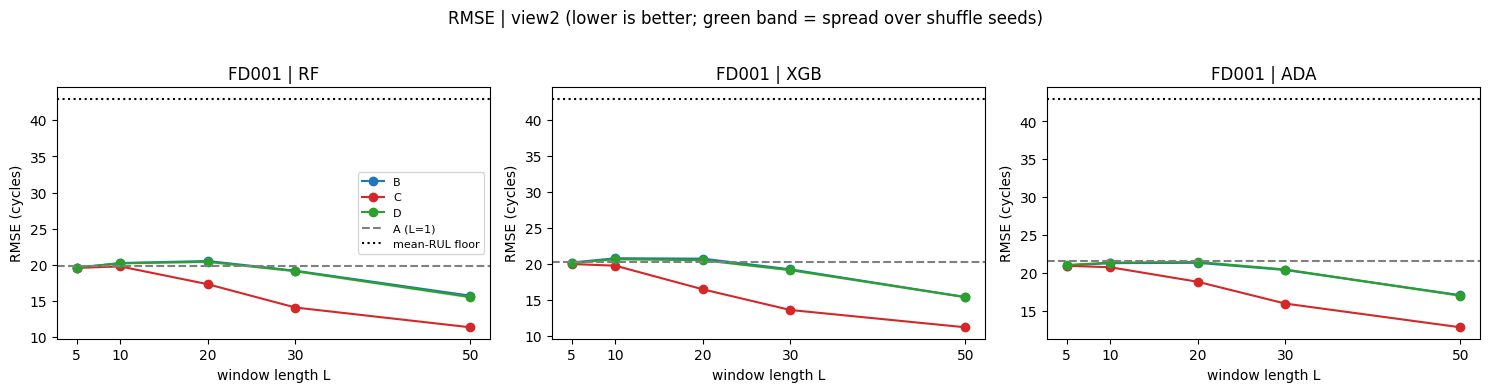

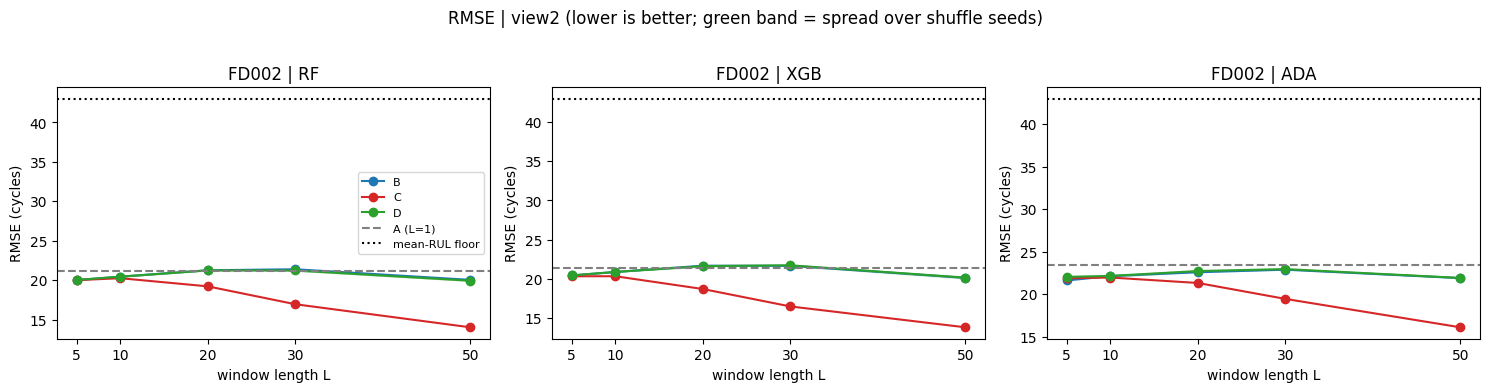

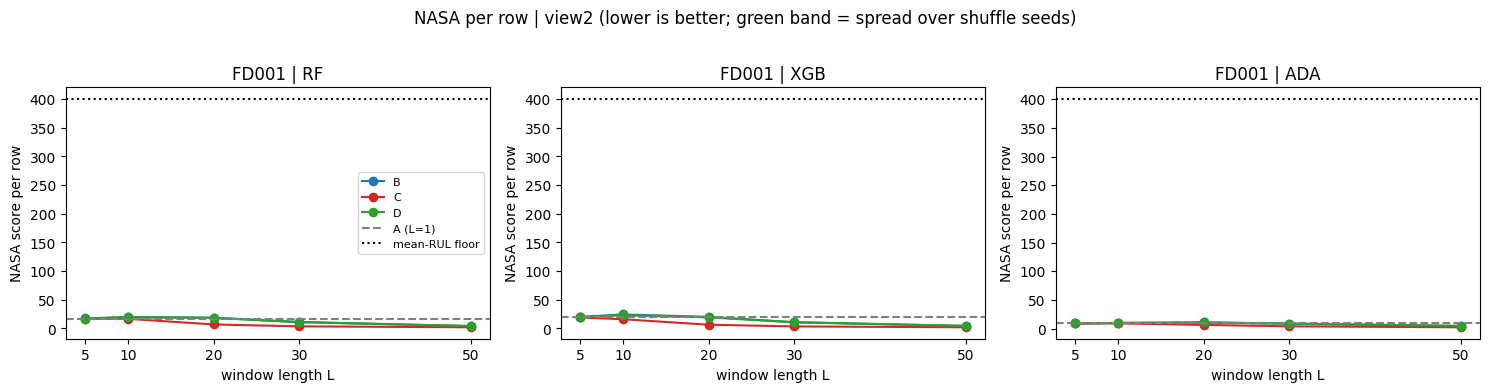

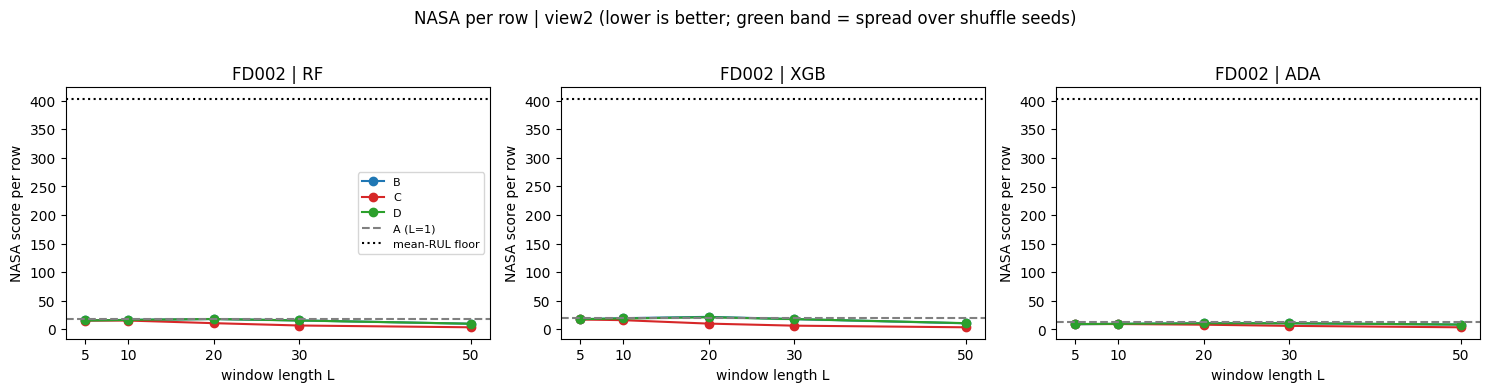

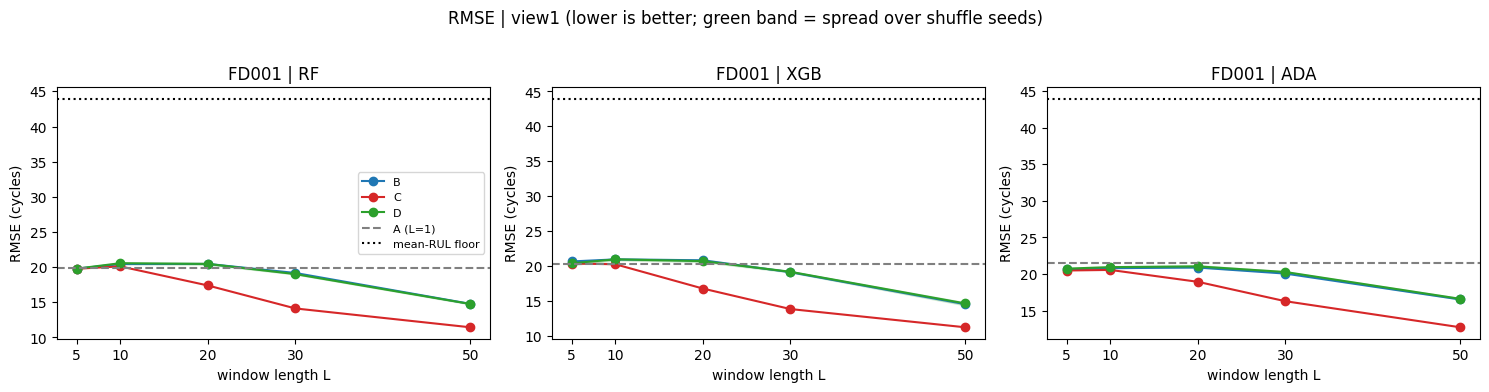

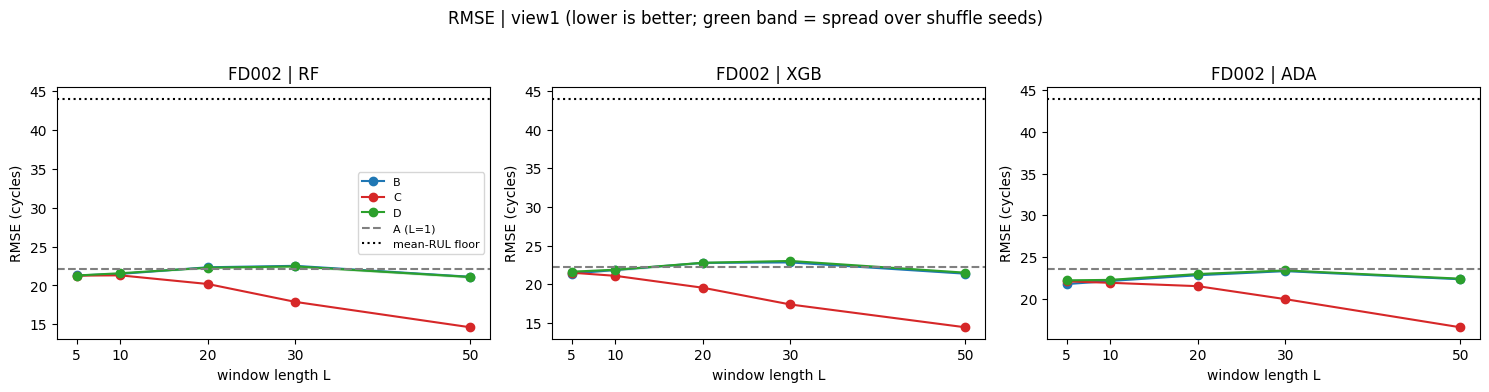

In [ ]:
COL = {"A": "gray", "B": "tab:blue", "C": "tab:red", "D": "tab:green", "Floor": "black"}
def plot_vs_L(sel, metric="rmse", fname=None):
    S = SUM[sel]; sd = fold_metrics(sel, keep_seed=True)
    sd = sd.groupby(KEYS + ["seed"], observed=True)[metric].mean().reset_index()
    for ds in DATASETS:
        fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 3.8), squeeze=False)
        for ax, m in zip(axes[0], MODELS):
            s = S[(S.dataset == ds) & (S.model == m)]; col = metric + "_mean" if metric == "rmse" else "nasa_row_mean"
            for c in ["B", "C", "D"]:
                t = s[s.cond == c].sort_values("L"); ax.plot(t.L, t[col], marker="o", color=COL[c], label=c)
            b = sd[(sd.dataset == ds) & (sd.model == m) & (sd.cond == "D")].groupby("L")[metric].agg(["min", "max"])
            ax.fill_between(b.index, b["min"], b["max"], color=COL["D"], alpha=.2)
            ax.axhline(s[s.cond == "A"][col].values[0], color=COL["A"], ls="--", label="A (L=1)")
            ax.axhline(S[(S.dataset == ds) & (S.model == "Floor")][col].values[0], color="k", ls=":", label="mean-RUL floor")
            ax.set_title(f"{ds} | {m}"); ax.set_xlabel("window length L"); ax.set_xticks(WINDOWS)
            ax.set_ylabel("RMSE (cycles)" if metric == "rmse" else "NASA score per row")
        axes[0, 0].legend(fontsize=8)
        plt.suptitle(f"{'RMSE' if metric == 'rmse' else 'NASA per row'} | {sel} (lower is better; green band = spread over shuffle seeds)", y=1.02)
        plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_{ds}_{sel}_{metric}.png", dpi=120, bbox_inches="tight"); plt.show()

plot_vs_L("view2", "rmse"); plot_vs_L("view2", "nasa_row"); plot_vs_L("view1", "rmse")

## 8. Paired differences with engine-level bootstrap
* **C - B** (main): does the true trend add anything on top of averaging? Negative = trend helps.
* **B - A**: benefit of averaging over one cycle.
* **C - D**: real order versus shuffled order.

Each difference is computed on the **same held-out engines**. Uncertainty comes from resampling **engines** (not rows), because cycles of one engine are correlated.

In [ ]:
G = {k: v for k, v in eng.groupby(["dataset", "model", "L", "cond"], observed=True)}

def engine_vec(ds, model, cond, L, sel):
    e = G[(ds, model, L, cond)]; e = e[sel_mask(e, sel)]
    return e.groupby(["seed", "unit"])[["n", "sse", "nasa"]].sum().groupby("unit").mean()      # D: average over seeds

def paired_boot(ds, model, L, c1, c2, sel):
    L1, L2 = (1 if c1 == "A" else L), (1 if c2 == "A" else L)
    v1, v2 = engine_vec(ds, model, c1, L1, sel), engine_vec(ds, model, c2, L2, sel)
    idx = v1.index.intersection(v2.index); v1, v2 = v1.loc[idx], v2.loc[idx]
    k = (v1.n > 0).values; v1, v2 = v1[k], v2[k]; n, s1, s2, a1, a2 = v1.n.values, v1.sse.values, v2.sse.values, v1.nasa.values, v2.nasa.values
    point_r = np.sqrt(s1.sum() / n.sum()) - np.sqrt(s2.sum() / n.sum()); point_n = (a1.sum() - a2.sum()) / n.sum()
    b = np.random.default_rng(SEED).integers(0, len(n), (N_BOOT, len(n))); N = n[b].sum(1)
    dr = np.sqrt(s1[b].sum(1) / N) - np.sqrt(s2[b].sum(1) / N); dn = (a1[b].sum(1) - a2[b].sum(1)) / N
    return dict(delta_rmse=point_r, rmse_lo=np.percentile(dr, 2.5), rmse_hi=np.percentile(dr, 97.5),
                delta_nasa_row=point_n, nasa_lo=np.percentile(dn, 2.5), nasa_hi=np.percentile(dn, 97.5), engines=len(n), rows=int(n.sum()))

CONTRASTS = [("C", "B"), ("B", "A"), ("C", "D")]
rows = []
for ds in DATASETS:
    for m in MODELS:
        for L in WINDOWS:
            for sel in SEL_ALL:
                for c1, c2 in CONTRASTS:
                    rows.append(dict(dataset=ds, model=m, L=L, sel=sel, c1=c1, c2=c2, **paired_boot(ds, m, L, c1, c2, sel)))
CT = pd.DataFrame(rows); CT.round(4).to_csv(f"{OUT_DIR}/paired_differences.csv", index=False)
print("Main contrast C - B, all cycles >= 50 (negative = trend features help). Interval = 95% engine bootstrap.")
t = CT[(CT.c1 == "C") & (CT.c2 == "B") & (CT.sel == "view2")].copy()
t["dRMSE (95% CI)"] = t.delta_rmse.round(2).astype(str) + " [" + t.rmse_lo.round(2).astype(str) + ", " + t.rmse_hi.round(2).astype(str) + "]"
display(t.pivot_table(index=["dataset", "model"], columns="L", values="dRMSE (95% CI)", aggfunc="first"))

Main contrast C - B, all cycles >= 50 (negative = trend features help). Interval = 95% engine bootstrap.


L                               5                     10                    20                    30                    50
dataset model                                                                                                             
FD001   ADA    -0.03 [-0.15, 0.08]  -0.55 [-0.81, -0.26]   -2.5 [-3.01, -1.91]  -4.44 [-5.22, -3.65]  -4.24 [-4.87, -3.62]
        RF     -0.02 [-0.09, 0.06]  -0.47 [-0.62, -0.32]  -3.22 [-3.91, -2.54]   -5.14 [-6.3, -3.97]  -4.39 [-5.24, -3.52]
        XGB    -0.2 [-0.32, -0.07]  -1.03 [-1.28, -0.77]  -4.26 [-5.13, -3.36]  -5.67 [-6.64, -4.62]   -4.25 [-5.1, -3.45]
FD002   ADA      0.22 [0.03, 0.43]  -0.18 [-0.27, -0.07]  -1.29 [-1.58, -0.98]  -3.45 [-3.87, -3.02]   -5.79 [-6.2, -5.38]
        RF     -0.01 [-0.05, 0.03]   -0.2 [-0.25, -0.14]  -2.05 [-2.32, -1.76]   -4.47 [-5.0, -3.95]  -6.03 [-6.73, -5.35]
        XGB    -0.1 [-0.17, -0.03]  -0.54 [-0.66, -0.43]   -3.0 [-3.41, -2.57]  -5.23 [-5.87, -4.58]   -6.33 [-7.03, -5.6]

## 9. Plot 2: C - B with uncertainty (main result)

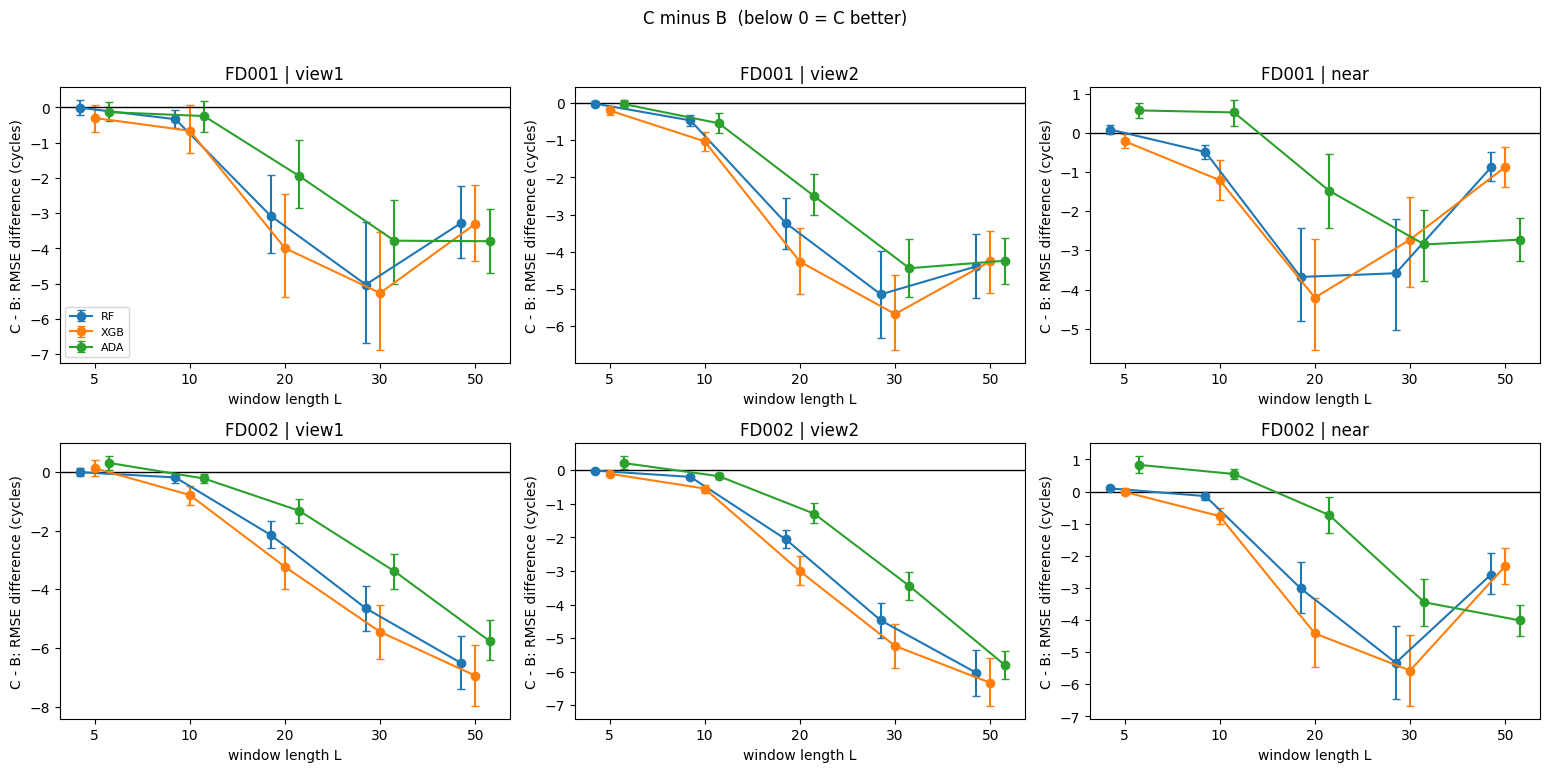

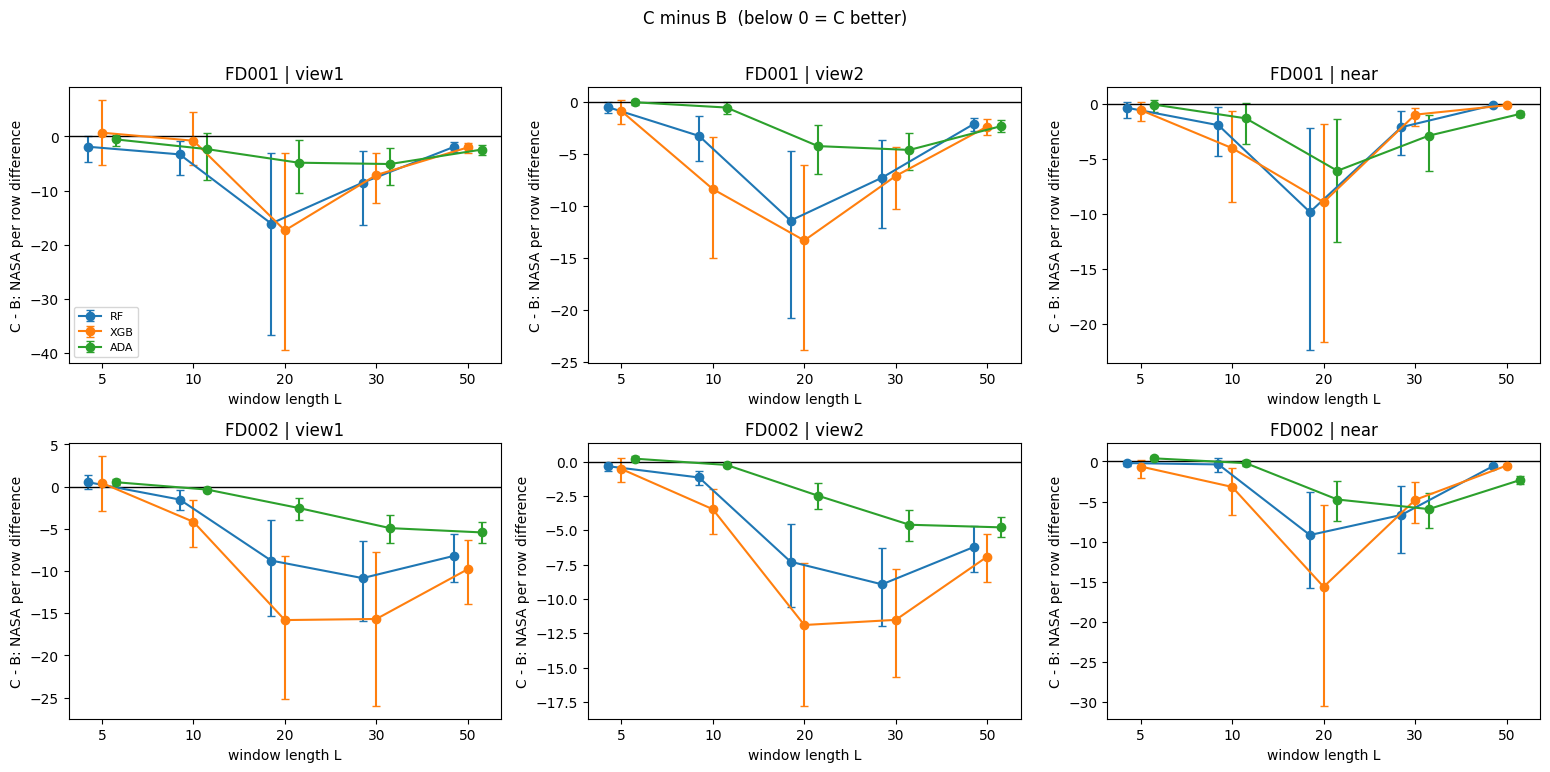

In [ ]:
def plot_delta(c1, c2, sels, metric="rmse", fname=""):
    cols = {"rmse": ("delta_rmse", "rmse_lo", "rmse_hi", "RMSE difference (cycles)"),
            "nasa": ("delta_nasa_row", "nasa_lo", "nasa_hi", "NASA per row difference")}[metric]
    fig, axes = plt.subplots(len(DATASETS), len(sels), figsize=(5.2 * len(sels), 3.8 * len(DATASETS)), squeeze=False)
    for i, ds in enumerate(DATASETS):
        for j, sel in enumerate(sels):
            ax = axes[i, j]
            for k, m in enumerate(MODELS):
                t = CT[(CT.dataset == ds) & (CT.model == m) & (CT.c1 == c1) & (CT.c2 == c2) & (CT.sel == sel)].sort_values("L")
                x = np.arange(len(t)) + (k - 1) * 0.15
                ax.errorbar(x, t[cols[0]], yerr=[t[cols[0]] - t[cols[1]], t[cols[2]] - t[cols[0]]], marker="o", capsize=3, label=m)
            ax.axhline(0, color="k", lw=1); ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS)
            ax.set_title(f"{ds} | {sel}"); ax.set_xlabel("window length L"); ax.set_ylabel(f"{c1} - {c2}: {cols[3]}")
    axes[0, 0].legend(fontsize=8)
    plt.suptitle(f"{c1} minus {c2}  (below 0 = {c1} better)", y=1.01); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig2_{c1}_minus_{c2}_{metric}.png", dpi=120, bbox_inches="tight"); plt.show()

plot_delta("C", "B", ["view1", "view2", "near"], "rmse")
plot_delta("C", "B", ["view1", "view2", "near"], "nasa")

## 10. Plot 3: early life vs middle vs near failure (does trend help mainly near failure?)

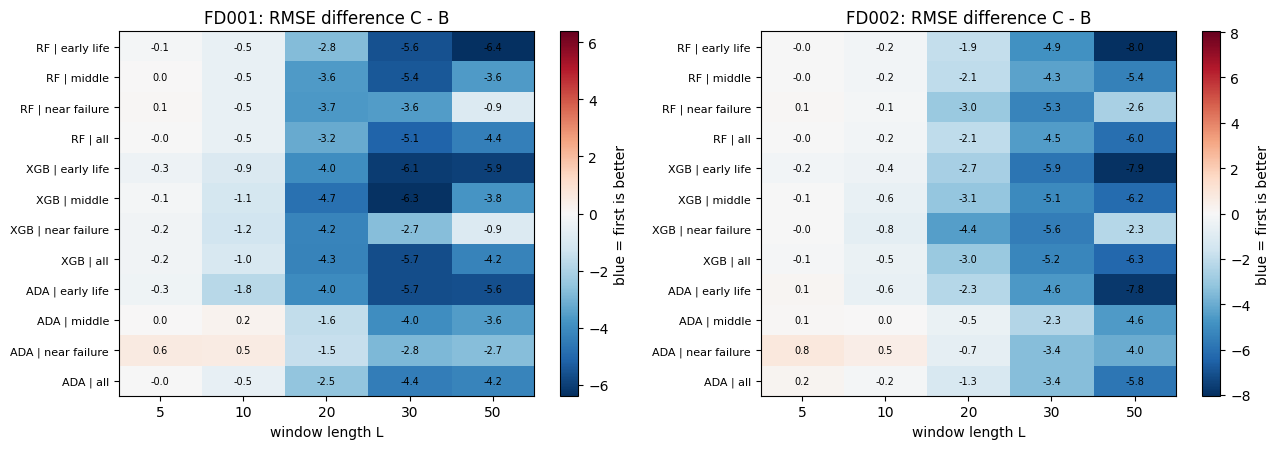

In [ ]:
def heat(c1, c2):
    sels = ["early", "mid", "near", "view2"]; labels = ["early life", "middle", "near failure", "all"]
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.5 * len(DATASETS), 4.6), squeeze=False)
    for ax, ds in zip(axes[0], DATASETS):
        M = np.array([[CT[(CT.dataset == ds) & (CT.model == m) & (CT.c1 == c1) & (CT.c2 == c2) & (CT.sel == s) & (CT.L == L)].delta_rmse.values[0]
                       for L in WINDOWS] for m in MODELS for s in sels])
        v = np.abs(M).max() + 1e-9; im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
        ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS); ax.set_xlabel("window length L")
        ax.set_yticks(range(len(M))); ax.set_yticklabels([f"{m} | {l}" for m in MODELS for l in labels], fontsize=8)
        for r in range(M.shape[0]):
            for c in range(M.shape[1]): ax.text(c, r, f"{M[r, c]:.1f}", ha="center", va="center", fontsize=7)
        ax.set_title(f"{ds}: RMSE difference {c1} - {c2}"); plt.colorbar(im, ax=ax, label="blue = first is better")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_heat_{c1}_minus_{c2}.png", dpi=120); plt.show()
heat("C", "B")

## 11. Plot 4: where does the gain come from? (A to B to C, and C vs D)

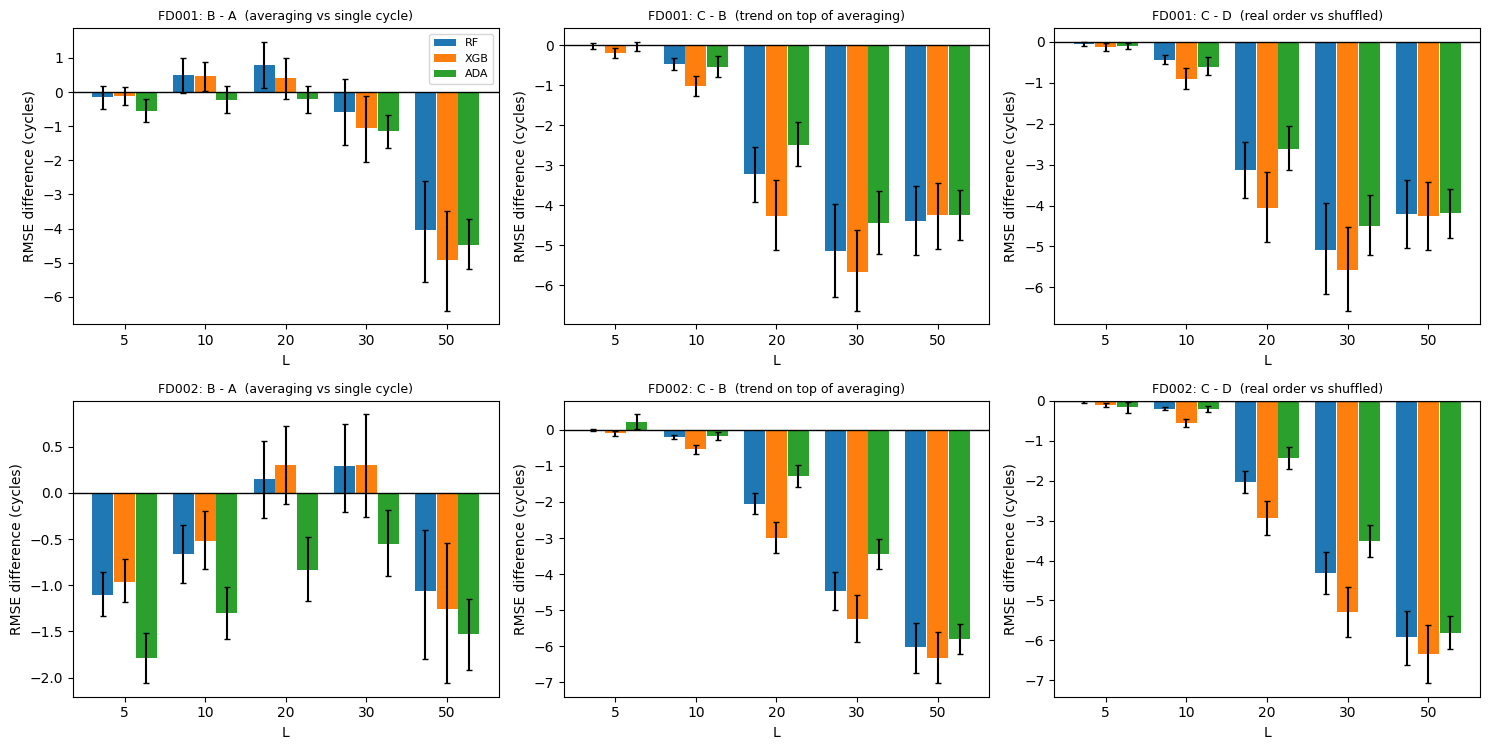

In [ ]:
def steps_plot(sel="view2"):
    fig, axes = plt.subplots(len(DATASETS), 3, figsize=(15, 3.8 * len(DATASETS)), squeeze=False)
    for i, ds in enumerate(DATASETS):
        for j, (c1, c2, name) in enumerate([("B", "A", "B - A  (averaging vs single cycle)"), ("C", "B", "C - B  (trend on top of averaging)"),
                                           ("C", "D", "C - D  (real order vs shuffled)")]):
            ax = axes[i, j]
            for k, m in enumerate(MODELS):
                t = CT[(CT.dataset == ds) & (CT.model == m) & (CT.c1 == c1) & (CT.c2 == c2) & (CT.sel == sel)].sort_values("L")
                ax.bar(np.arange(len(t)) + (k - 1) * 0.27, t.delta_rmse, width=0.26, label=m,
                       yerr=[t.delta_rmse - t.rmse_lo, t.rmse_hi - t.delta_rmse], capsize=2)
            ax.axhline(0, color="k", lw=1); ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS)
            ax.set_title(f"{ds}: {name}", fontsize=9); ax.set_xlabel("L"); ax.set_ylabel("RMSE difference (cycles)")
    axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_steps.png", dpi=120); plt.show()
steps_plot()

## 12. Verdict table
Rule fixed in advance: an effect is called **real** only if, for all three models, the 95% engine-bootstrap interval excludes 0, the sign agrees in at least 4 of 5 folds, and the sign is the same across models. Otherwise: **no clear effect**.

In [ ]:
def verdict(c1, c2, sel):
    out = []
    for ds in DATASETS:
        for L in WINDOWS:
            ok, signs = [], []
            for m in MODELS:
                r = CT[(CT.dataset == ds) & (CT.model == m) & (CT.L == L) & (CT.c1 == c1) & (CT.c2 == c2) & (CT.sel == sel)].iloc[0]
                f = FM[sel].set_index(KEYS + ["fold"]).rmse
                fd = np.array([f[(ds, m, 1 if c1 == "A" else L, c1, fo)] - f[(ds, m, 1 if c2 == "A" else L, c2, fo)] for fo in range(N_FOLDS)])
                sg = np.sign(r.delta_rmse); signs.append(sg)
                ok.append((r.rmse_lo > 0 or r.rmse_hi < 0) and (np.sign(fd) == sg).sum() >= 4)
            res = "no clear effect"
            if all(ok) and len(set(signs)) == 1: res = f"{c1} better" if signs[0] < 0 else f"{c2} better"
            out.append(dict(dataset=ds, L=L, view=sel, contrast=f"{c1} - {c2}", verdict=res,
                            mean_dRMSE=CT[(CT.dataset == ds) & (CT.L == L) & (CT.c1 == c1) & (CT.c2 == c2) & (CT.sel == sel)].delta_rmse.mean().round(2)))
    return pd.DataFrame(out)

V = pd.concat([verdict(c1, c2, s) for (c1, c2) in CONTRASTS for s in ["view1", "view2", "near"]], ignore_index=True)
V.to_csv(f"{OUT_DIR}/verdicts.csv", index=False)
display(V[V.contrast == "C - B"].pivot_table(index=["dataset", "L"], columns="view", values="verdict", aggfunc="first"))
display(V[V.contrast == "B - A"].pivot_table(index=["dataset", "L"], columns="view", values="verdict", aggfunc="first"))
display(V[V.contrast == "C - D"].pivot_table(index=["dataset", "L"], columns="view", values="verdict", aggfunc="first"))

view                   near            view1            view2
dataset L                                                    
FD001   5   no clear effect  no clear effect  no clear effect
        10  no clear effect  no clear effect         C better
        20         C better         C better         C better
        30         C better         C better         C better
        50         C better         C better         C better
FD002   5   no clear effect  no clear effect  no clear effect
        10  no clear effect         C better         C better
        20         C better         C better         C better
        30         C better         C better         C better
        50         C better         C better         C better

view                   near            view1            view2
dataset L                                                    
FD001   5          B better  no clear effect  no clear effect
        10  no clear effect  no clear effect  no clear effect
        20  no clear effect  no clear effect  no clear effect
        30         B better  no clear effect  no clear effect
        50         B better         B better         B better
FD002   5          B better         B better         B better
        10         B better  no clear effect         B better
        20  no clear effect  no clear effect  no clear effect
        30         B better  no clear effect  no clear effect
        50         B better  no clear effect         B better

view                   near            view1            view2
dataset L                                                    
FD001   5   no clear effect  no clear effect  no clear effect
        10  no clear effect  no clear effect         C better
        20         C better         C better         C better
        30         C better         C better         C better
        50         C better         C better         C better
FD002   5   no clear effect  no clear effect  no clear effect
        10  no clear effect         C better         C better
        20         C better         C better         C better
        30         C better         C better         C better
        50         C better         C better         C better

## 13. Final test on the official test set (run once)
* Retrain on **all** training engines. Normalizer fitted on all training engines.
* For each model and condition (A, B, C) we use the window length that had the lowest cross-validated RMSE in View 1. The test set was not used for this choice.
* Official test engines stop at a random cycle, and some have fewer than L cycles. Rule: if an engine is shorter than L, the first reading is repeated at the front. Applied the same way to B and C.
* Scored against the capped true RUL (same cap as training). D is not run here (it is only a diagnostic).

In [ ]:
import joblib
MODEL_DIR = f"{OUT_DIR}/models"; os.makedirs(MODEL_DIR, exist_ok=True)

def save_bundle(ds, model_name, cond, L, model, norm):
    d = DATA[ds]
    bundle = dict(dataset=ds, model_name=model_name, cond=cond, L=L, model=model,
                  sensors=d["sensors"], settings=SETTINGS, RUL_CAP=RUL_CAP,
                  norm=dict(k=norm.k, mu=norm.mu, sd=norm.sd, km=getattr(norm, "km", None),
                            s_mu=getattr(norm, "s_mu", None), s_sd=getattr(norm, "s_sd", None)))
    path = f"{MODEL_DIR}/{ds}_{model_name}_{cond}_L{L}.pkl"
    joblib.dump(bundle, path)
    return path

,dataset,model,cond,L,rmse,nasa,nasa_per_engine
0,FD001,Floor,Floor,0,41.942,33354.472,333.545
1,FD001,RF,A,1,17.244,791.932,7.919
2,FD001,RF,B,50,17.528,776.494,7.765
3,FD001,RF,C,50,13.020,260.065,2.601
4,FD001,XGB,A,1,18.356,1100.579,11.006
5,FD001,XGB,B,50,17.538,844.186,8.442
6,FD001,XGB,C,50,13.206,276.717,2.767
7,FD001,ADA,A,1,20.075,923.154,9.232
8,FD001,ADA,B,50,17.948,644.462,6.445
9,FD001,ADA,C,50,13.817,271.770,2.718


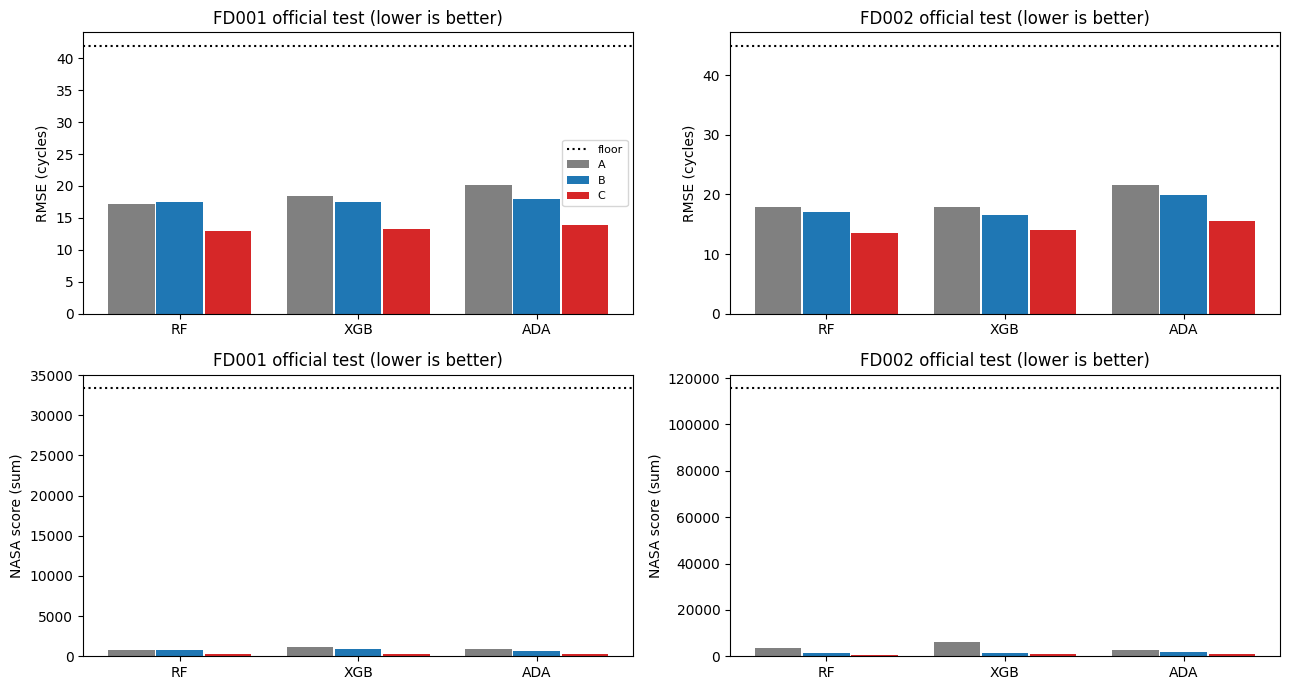

In [ ]:
def test_X(Xte, tegroups, L, mode):
    feats = []
    for u in sorted(tegroups):
        a = Xte[tegroups[u]]
        if len(a) < L: a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])      # padding rule for short engines
        feats.append(window_feats(a[-L:].T[None], mode)[0])
    return np.array(feats)

best = SUM["view1"][SUM["view1"].cond.isin(["A", "B", "C"]) & SUM["view1"].model.isin(MODELS)]
best = best.loc[best.groupby(["dataset", "model", "cond"], observed=True).rmse_mean.idxmin()].set_index(["dataset", "model", "cond"]).L

test_rows = []
for ds in DATASETS:
    d = DATA[ds]; df, te = d["train"], d["test"]; sensors, groups = d["sensors"], d["groups"]
    norm = Normalizer(d["n_regimes"]).fit(df, sensors); Xtr, Xte = norm.transform(df), norm.transform(te)
    units = np.array(sorted(d["fold_of"])); tegroups = te.groupby("unit_id").indices
    ytrue = np.minimum(d["rul"], RUL_CAP).astype(float); assert len(ytrue) == len(tegroups)
    p = np.full(len(ytrue), df["y"].mean())
    test_rows.append(dict(dataset=ds, model="Floor", cond="Floor", L=0, rmse=rmse(ytrue, p), nasa=nasa_score(ytrue, p)))
    for m in MODELS:
        for cond in ["A", "B", "C"]:
            L = int(best[(ds, m, cond)])
            Xf, rows_ = build(Xtr, groups, units, L, cond, L, TRAIN_STRIDE); yf = df["y"].values[rows_]
            mdl = make_model(m).fit(Xf, yf)
            p = np.clip(mdl.predict(test_X(Xte, tegroups, L, cond)), 0, RUL_CAP)
            save_bundle(ds, m, cond, L, mdl, norm)
            test_rows.append(dict(dataset=ds, model=m, cond=cond, L=L, rmse=rmse(ytrue, p), nasa=nasa_score(ytrue, p)))
TEST = pd.DataFrame(test_rows); TEST["nasa_per_engine"] = TEST.nasa / TEST.dataset.map({ds: len(DATA[ds]["rul"]) for ds in DATASETS})
TEST.round(3).to_csv(f"{OUT_DIR}/final_test.csv", index=False)
display(TEST.round(3))

fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.5 * len(DATASETS), 7), squeeze=False)
for j, ds in enumerate(DATASETS):
    for i, (col, lab) in enumerate([("rmse", "RMSE (cycles)"), ("nasa", "NASA score (sum)")]):
        ax = axes[i, j]; t = TEST[(TEST.dataset == ds) & (TEST.model != "Floor")]
        for k, c in enumerate(["A", "B", "C"]):
            v = [t[(t.model == m) & (t.cond == c)][col].values[0] for m in MODELS]
            ax.bar(np.arange(len(MODELS)) + (k - 1) * 0.27, v, width=0.26, color=COL[c], label=c)
        ax.axhline(TEST[(TEST.dataset == ds) & (TEST.model == "Floor")][col].values[0], color="k", ls=":", label="floor")
        ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS); ax.set_ylabel(lab); ax.set_title(f"{ds} official test (lower is better)")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig5_final_test.png", dpi=120); plt.show()

In [ ]:
d2 = DATA["FD002"]
nm = Normalizer(6).fit(d2["train"], d2["sensors"])
reg = nm._regime(d2["train"])
print(np.bincount(reg))
print(d2["train"][SETTINGS].round(1).drop_duplicates().shape[0], "distinct settings combos after rounding")

[13458  8044  8122  8002  8096  8037]
7 distinct settings combos after rounding


## 14. How to read the results (fill in after running)
| What you see | Meaning |
|---|---|
| B better than A, C about equal to B | Averaging helps, trend adds little. This matches our guess. |
| C better than B and D, interval excludes 0 | Real order carries extra information. |
| C - B gets more negative as L grows | Trend matters more with longer windows. |
| C - B more negative in the near-failure group | Trend matters mostly when degradation is strong. |
| C worse than B | Trend features are noisy or redundant here. |
| All similar | No measurable benefit under this design. A valid result. |

**Limits to state in your report:** shuffling is a diagnostic, not a clean removal of order; cycles of one engine are correlated (so we bootstrap engines); folds are not fully independent; FD001 results may not carry over to FD002; training windows use every 4th cycle to save time; the cap is 125; the test set has only 100 (FD001) and 259 (FD002) engines, so test numbers are noisy.

In [ ]:
import joblib
MODEL_DIR = f"{OUT_DIR}/models"; os.makedirs(MODEL_DIR, exist_ok=True)

def save_bundle(ds, model_name, cond, L, model, norm):
    d = DATA[ds]
    bundle = dict(dataset=ds, model_name=model_name, cond=cond, L=L, model=model,
                  sensors=d["sensors"], settings=SETTINGS, RUL_CAP=RUL_CAP,
                  norm=dict(k=norm.k, mu=norm.mu, sd=norm.sd, km=getattr(norm, "km", None),
                            s_mu=getattr(norm, "s_mu", None), s_sd=getattr(norm, "s_sd", None)))
    path = f"{MODEL_DIR}/{ds}_{model_name}_{cond}_L{L}.pkl"
    joblib.dump(bundle, path)
    return path

In [ ]:
import joblib

def apply_norm(b, df):
    n = b["norm"]
    reg = np.zeros(len(df), int) if n["k"] == 1 else n["km"].predict((df[b["settings"]].values - n["s_mu"]) / n["s_sd"])
    return (df[b["sensors"]].values - n["mu"][reg]) / n["sd"][reg]

def predict_rul(b, engine_df):
    X = apply_norm(b, engine_df.sort_values("cycle")); L = b["L"]
    if len(X) < L: X = np.vstack([np.repeat(X[:1], L - len(X), 0), X])      # same padding rule as the test
    f = window_feats(X[-L:].T[None], b["cond"])
    return float(np.clip(b["model"].predict(f)[0], 0, b["RUL_CAP"]))

b = joblib.load(f"{MODEL_DIR}/FD001_RF_C_L50.pkl")        # use the real file name from the folder
e = DATA["FD001"]["test"]; e = e[e.unit_id == 1]            # all recorded cycles of test engine 1
print("Predicted RUL:", predict_rul(b, e))

Predicted RUL: 106.49644073519072


,dataset,model,cond,L,rmse,nasa,padded_engines,rmse_sd,nasa_sd,nasa_per_engine
0,FD001,Floor,Floor,0,41.942,33354.472,NaN,NaN,NaN,333.545
1,FD001,RF,A,1,17.244,791.932,0.0,NaN,NaN,7.919
2,FD001,RF,B,50,17.528,776.494,7.0,NaN,NaN,7.765
3,FD001,RF,C,50,13.020,260.065,7.0,NaN,NaN,2.601
4,FD001,RF,D,50,17.326,730.096,7.0,0.100,13.223,7.301
5,FD001,XGB,A,1,18.356,1100.579,0.0,NaN,NaN,11.006
6,FD001,XGB,B,50,17.538,844.186,7.0,NaN,NaN,8.442
7,FD001,XGB,C,50,13.206,276.717,7.0,NaN,NaN,2.767
8,FD001,XGB,D,50,17.440,852.664,7.0,0.276,22.552,8.527
9,FD001,ADA,A,1,20.075,923.154,0.0,NaN,NaN,9.232


Saved models: 36 files in /kaggle/working/models


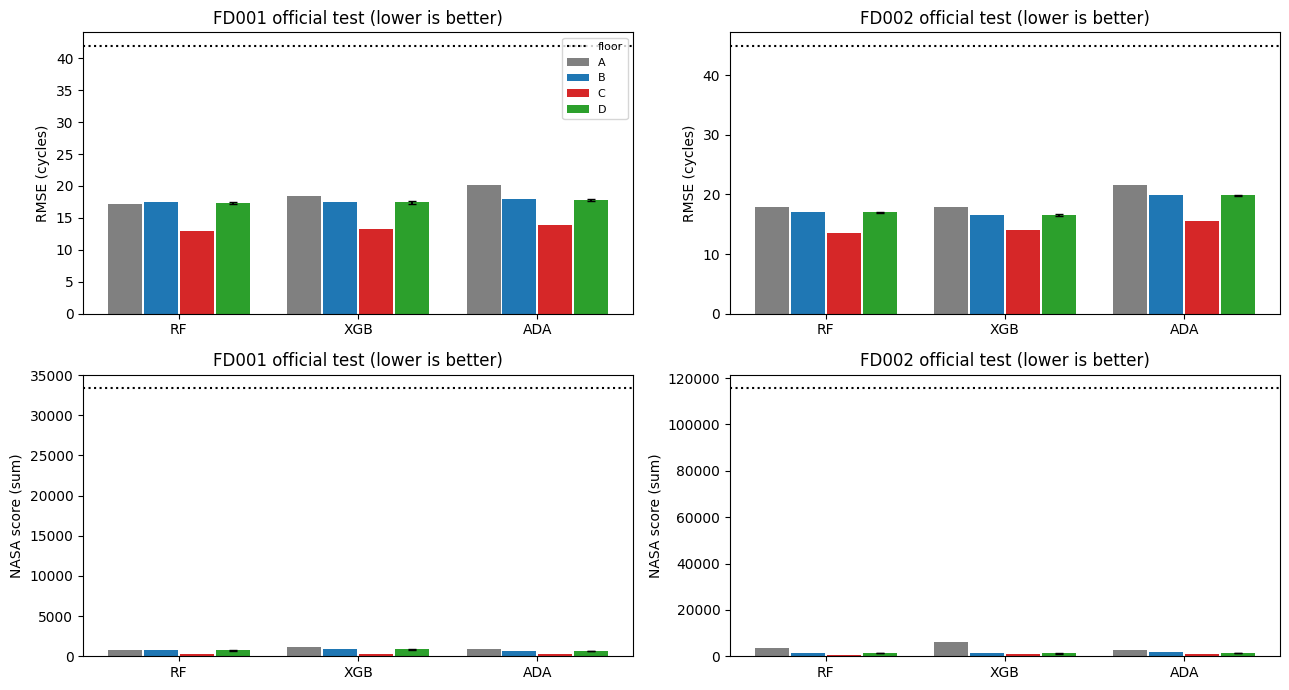

In [ ]:
import joblib
MODEL_DIR = f"{OUT_DIR}/models"; os.makedirs(MODEL_DIR, exist_ok=True)

def save_bundle(ds, model_name, cond, L, model, norm, seed=None):
    d = DATA[ds]
    bundle = dict(dataset=ds, model_name=model_name, cond=cond, L=L, seed=seed, model=model,
                  sensors=d["sensors"], settings=SETTINGS, RUL_CAP=RUL_CAP,
                  norm=dict(k=norm.k, mu=norm.mu, sd=norm.sd, km=getattr(norm, "km", None),
                            s_mu=getattr(norm, "s_mu", None), s_sd=getattr(norm, "s_sd", None)))
    name = f"{ds}_{model_name}_{cond}_L{L}" + (f"_seed{seed}" if seed is not None else "")
    joblib.dump(bundle, f"{MODEL_DIR}/{name}.pkl")

def test_X(Xte, tegroups, L, mode, rng=None):
    """One window per test engine: its last L cycles (first reading repeated if the engine is shorter than L)."""
    feats = []
    for u in sorted(tegroups):
        a = Xte[tegroups[u]]
        if len(a) < L: a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])
        feats.append(window_feats(a[-L:].T[None], mode, rng)[0])
    return np.array(feats)

# window length per model: the L with the lowest cross-validated View 1 RMSE (test set not used for this choice)
best = SUM["view1"][SUM["view1"].cond.isin(["A", "B", "C"]) & SUM["view1"].model.isin(MODELS)]
best = best.loc[best.groupby(["dataset", "model", "cond"], observed=True).rmse_mean.idxmin()].set_index(["dataset", "model", "cond"]).L

test_rows = []
for ds in DATASETS:
    d = DATA[ds]; df, te = d["train"], d["test"]; sensors, groups = d["sensors"], d["groups"]
    norm = Normalizer(d["n_regimes"]).fit(df, sensors); Xtr, Xte = norm.transform(df), norm.transform(te)
    units = np.array(sorted(d["fold_of"])); tegroups = te.groupby("unit_id").indices
    test_len = np.array([len(tegroups[u]) for u in sorted(tegroups)])
    ytrue = np.minimum(d["rul"], RUL_CAP).astype(float); assert len(ytrue) == len(tegroups)
    p = np.full(len(ytrue), df["y"].mean())
    test_rows.append(dict(dataset=ds, model="Floor", cond="Floor", L=0, rmse=rmse(ytrue, p), nasa=nasa_score(ytrue, p)))
    for m in MODELS:
        # A, B, C: one model each
        for cond in ["A", "B", "C"]:
            L = int(best[(ds, m, cond)])
            Xf, rows_ = build(Xtr, groups, units, L, cond, L, TRAIN_STRIDE); yf = df["y"].values[rows_]
            mdl = make_model(m).fit(Xf, yf)
            p = np.clip(mdl.predict(test_X(Xte, tegroups, L, cond)), 0, RUL_CAP)
            save_bundle(ds, m, cond, L, mdl, norm)
            test_rows.append(dict(dataset=ds, model=m, cond=cond, L=L, rmse=rmse(ytrue, p), nasa=nasa_score(ytrue, p),
                                  padded_engines=int((test_len < L).sum())))
        # D: same L as C, one model per shuffle seed; shuffled in training windows AND in the test window
        L = int(best[(ds, m, "C")]); r, n = [], []
        for seed in range(D_SEEDS):
            rng = np.random.default_rng(10_000 * seed + 100 * L + 999)
            Xf, rows_ = build(Xtr, groups, units, L, "D", L, TRAIN_STRIDE, rng); yf = df["y"].values[rows_]
            mdl = make_model(m).fit(Xf, yf)
            p = np.clip(mdl.predict(test_X(Xte, tegroups, L, "D", rng)), 0, RUL_CAP)
            save_bundle(ds, m, "D", L, mdl, norm, seed=seed)
            r.append(rmse(ytrue, p)); n.append(nasa_score(ytrue, p))
        test_rows.append(dict(dataset=ds, model=m, cond="D", L=L, rmse=np.mean(r), nasa=np.mean(n),
                              rmse_sd=np.std(r), nasa_sd=np.std(n), padded_engines=int((test_len < L).sum())))

TEST = pd.DataFrame(test_rows)
TEST["nasa_per_engine"] = TEST.nasa / TEST.dataset.map({ds: len(DATA[ds]["rul"]) for ds in DATASETS})
TEST.round(3).to_csv(f"{OUT_DIR}/final_test.csv", index=False)
display(TEST.round(3))
print("Saved models:", len(os.listdir(MODEL_DIR)), "files in", MODEL_DIR)

fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.5 * len(DATASETS), 7), squeeze=False)
for j, ds in enumerate(DATASETS):
    for i, (col, lab) in enumerate([("rmse", "RMSE (cycles)"), ("nasa", "NASA score (sum)")]):
        ax = axes[i, j]; t = TEST[(TEST.dataset == ds) & (TEST.model != "Floor")]
        for k, c in enumerate(["A", "B", "C", "D"]):
            v = [t[(t.model == m) & (t.cond == c)][col].values[0] for m in MODELS]
            e = [t[(t.model == m) & (t.cond == c)][col + "_sd"].values[0] for m in MODELS] if c == "D" else None
            ax.bar(np.arange(len(MODELS)) + (k - 1.5) * 0.2, v, width=0.19, color=COL[c], label=c, yerr=e, capsize=3)
        ax.axhline(TEST[(TEST.dataset == ds) & (TEST.model == "Floor")][col].values[0], color="k", ls=":", label="floor")
        ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS); ax.set_ylabel(lab); ax.set_title(f"{ds} official test (lower is better)")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig5_final_test.png", dpi=120); plt.show()

In [ ]:
from pathlib import Path
import zipfile

# Folder containing your saved models
MODEL_DIR = Path("/kaggle/working/models")

# ZIP file to create
ZIP_PATH = Path("/kaggle/working/models.zip")

if not MODEL_DIR.is_dir():
    raise FileNotFoundError(f"Models folder not found: {MODEL_DIR}")

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in MODEL_DIR.rglob("*"):
        if file.is_file():
            # Preserve the folder structure inside the ZIP
            zipf.write(file, arcname=file.relative_to(MODEL_DIR.parent))

print(f"ZIP created: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

ZIP created: /kaggle/working/models.zip
ZIP size: 54.96 MB


In [ ]:
r = nm._regime(d2["train"])
print(pd.crosstab(r, d2["train"][SETTINGS].round(0).astype(str).agg("_".join, axis=1)))

col_0  0.0_0.0_100.0  10.0_0.0_100.0  20.0_1.0_100.0  25.0_1.0_60.0  35.0_1.0_100.0  42.0_1.0_100.0
row_0                                                                                              
0                  0               0               0              0               0           13458
1               8044               0               0              0               0               0
2                  0               0            8122              0               0               0
3                  0               0               0           8002               0               0
4                  0            8096               0              0               0               0
5                  0               0               0              0            8037               0


In [ ]:
tr = DATA["FD001"]["train"]
print(tr[[c for c in tr.columns if c.startswith("sensor")]].std().sort_values().head(8))

sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
sensor_15    3.750504e-02
dtype: float64


In [ ]:
# ---- Hypothesis tests for Q1 (run after section 8; uses eng, engine_vec, N_BOOT, SEED from earlier cells) ----
def boot_fn(ds, m, needs, fn):
    """needs: list of (cond, sel, L). Resamples ENGINES; returns point estimate and 95% interval of fn(R)."""
    V = {k: engine_vec(ds, m, k[0], k[2], k[1]) for k in needs}
    idx = None
    for v in V.values(): idx = v.index if idx is None else idx.intersection(v.index)
    V = {k: v.loc[idx] for k, v in V.items()}
    keep = np.all([v.n.values > 0 for v in V.values()], axis=0); V = {k: v[keep] for k, v in V.items()}; E = int(keep.sum())
    B = np.vstack([np.arange(E), np.random.default_rng(SEED).integers(0, E, (N_BOOT, E))])     # row 0 = the real data
    R = {k: np.sqrt(v.sse.values[B].sum(1) / v.n.values[B].sum(1)) for k, v in V.items()}
    o = fn(R); return o[0], np.percentile(o[1:], 2.5), np.percentile(o[1:], 97.5)

Lmax = max(WINDOWS); rows = []
for ds in DATASETS:
    for m in MODELS:
        for L in WINDOWS:
            a, b, c, d = ("A", "view2", 1), ("B", "view2", L), ("C", "view2", L), ("D", "view2", L)
            tests = {
              "T1 trend gain minus averaging gain (>0: trend gain is bigger)":
                  ([a, b, c], lambda R: (R[b] - R[c]) - (R[a] - R[b])),
              "T2 trend gain near failure minus early life (>0: bigger near failure)":
                  ([("B", "near", L), ("C", "near", L), ("B", "early", L), ("C", "early", L)],
                   lambda R: (R[("B", "near", L)] - R[("C", "near", L)]) - (R[("B", "early", L)] - R[("C", "early", L)])),
              "T4 D minus B (0: shuffled trend features add nothing)": ([b, d], lambda R: R[d] - R[b]),
            }
            if L > WINDOWS[0]:
                tests["T3 trend gain at this L minus at L=%d (>0: longer window helps more)" % WINDOWS[0]] = (
                    [("B", "view2", WINDOWS[0]), ("C", "view2", WINDOWS[0]), b, c],
                    lambda R: (R[b] - R[c]) - (R[("B", "view2", WINDOWS[0])] - R[("C", "view2", WINDOWS[0])]))
            for name, (needs, fn) in tests.items():
                est, lo, hi = boot_fn(ds, m, needs, fn)
                rows.append(dict(dataset=ds, model=m, L=L, test=name, estimate=round(est, 2), ci=f"[{lo:.2f}, {hi:.2f}]",
                                 clear=("yes" if (lo > 0 or hi < 0) else "no")))
HYP = pd.DataFrame(rows); HYP.to_csv(f"{OUT_DIR}/hypothesis_tests.csv", index=False)
for t in HYP.test.unique():
    print("\n" + t); display(HYP[HYP.test == t].assign(res=lambda x: x.estimate.astype(str) + " " + x.ci + " " + x.clear.map({"yes": "*", "no": ""}))
                              .pivot_table(index=["dataset", "model"], columns="L", values="res", aggfunc="first"))
print("\n* = 95% engine-bootstrap interval excludes 0")


T1 trend gain minus averaging gain (>0: trend gain is bigger)


L                                  5                       10                   20                   30                    50
dataset model                                                                                                                
FD001   ADA    -0.54 [-0.92, -0.10] *     0.31 [-0.24, 0.87]   2.31 [1.43, 3.12] *   3.3 [2.20, 4.38] *  -0.25 [-1.26, 0.84] 
        RF       -0.14 [-0.53, 0.23]      0.96 [0.35, 1.55] *   4.0 [2.84, 5.13] *  4.57 [2.86, 6.41] *   0.34 [-1.67, 2.25] 
        XGB       0.08 [-0.24, 0.38]      1.51 [0.90, 2.06] *  4.68 [3.39, 5.86] *  4.61 [3.07, 6.14] *  -0.66 [-2.57, 1.18] 
FD002   ADA     -2.0 [-2.42, -1.61] *  -1.12 [-1.47, -0.79] *  0.46 [-0.14, 1.08]    2.9 [2.14, 3.63] *   4.26 [3.57, 4.93] *
        RF     -1.09 [-1.35, -0.82] *  -0.47 [-0.81, -0.12] *   2.2 [1.57, 2.83] *  4.76 [3.83, 5.66] *   4.96 [3.71, 6.12] *
        XGB    -0.86 [-1.12, -0.60] *     0.03 [-0.34, 0.42]   3.31 [2.56, 4.06] *  5.53 [4.43, 6.57] *   5.07 [3.78, 6.21] *


T2 trend gain near failure minus early life (>0: bigger near failure)


L                                  5                       10                      20                      30                      50
dataset model                                                                                                                        
FD001   ADA    -0.84 [-1.09, -0.61] *  -2.28 [-2.83, -1.71] *   -2.7 [-3.97, -1.50] *  -2.88 [-4.68, -1.24] *  -2.97 [-4.06, -1.88] *
        RF     -0.19 [-0.38, -0.02] *     0.01 [-0.30, 0.34]      0.47 [-0.92, 1.88]      -2.3 [-4.93, 0.09]   -5.65 [-7.51, -3.79] *
        XGB      -0.12 [-0.39, 0.15]      0.14 [-0.59, 0.80]     -0.27 [-2.19, 1.58]   -3.43 [-5.70, -1.26] *  -5.19 [-7.06, -3.25] *
FD002   ADA     -0.7 [-1.04, -0.30] *  -1.22 [-1.42, -1.02] *  -1.86 [-2.69, -1.09] *  -1.72 [-2.88, -0.66] *  -4.01 [-4.82, -3.20] *
        RF      -0.1 [-0.18, -0.01] *    -0.06 [-0.22, 0.09]       0.5 [-0.44, 1.44]     -0.47 [-1.96, 0.97]   -5.92 [-7.22, -4.56] *
        XGB    -0.22 [-0.36, -0.06] *      0.3 [-0.03, 0.63]       0.9 [-0.37, 2.07]     -1.15 [-2.79, 0.41]    -6.1 [-7.32, -4.77] *


T4 D minus B (0: shuffled trend features add nothing)


L                                5                     10                      20                      30                      50
dataset model                                                                                                                    
FD001   ADA     0.08 [-0.06, 0.22]    0.06 [-0.06, 0.19]      0.12 [-0.01, 0.25]      0.06 [-0.20, 0.29]     -0.05 [-0.21, 0.13] 
        RF      0.03 [-0.05, 0.10]   -0.03 [-0.11, 0.05]      -0.1 [-0.23, 0.04]     -0.06 [-0.23, 0.11]   -0.19 [-0.34, -0.02] *
        XGB    -0.07 [-0.17, 0.03]   -0.13 [-0.25, 0.00]   -0.21 [-0.36, -0.05] *     -0.1 [-0.25, 0.04]       0.0 [-0.16, 0.18] 
FD002   ADA     0.38 [0.23, 0.54] *   0.03 [-0.05, 0.11]      0.13 [0.07, 0.20] *     0.07 [0.00, 0.14] *     0.02 [-0.06, 0.11] 
        RF      0.02 [-0.02, 0.05]    -0.0 [-0.04, 0.03]     -0.01 [-0.06, 0.05]   -0.16 [-0.24, -0.08] *  -0.11 [-0.21, -0.00] *
        XGB     0.01 [-0.04, 0.06]    0.01 [-0.07, 0.09]     -0.06 [-0.16, 0.03]      0.06 [-0.05, 0.17]      0.02 [-0.10, 0.15]


T3 trend gain at this L minus at L=5 (>0: longer window helps more)


L                               10                   20                   30                   50
dataset model                                                                                    
FD001   ADA    0.52 [0.27, 0.74] *  2.47 [1.93, 2.95] *  4.41 [3.60, 5.16] *  4.21 [3.62, 4.85] *
        RF     0.45 [0.32, 0.57] *   3.2 [2.55, 3.86] *  5.12 [3.95, 6.29] *  4.37 [3.51, 5.21] *
        XGB    0.83 [0.57, 1.09] *  4.06 [3.16, 4.95] *  5.47 [4.44, 6.48] *  4.05 [3.24, 4.90] *
FD002   ADA    0.39 [0.24, 0.57] *  1.51 [1.18, 1.84] *  3.66 [3.21, 4.15] *  6.01 [5.54, 6.46] *
        RF     0.19 [0.13, 0.25] *  2.04 [1.76, 2.31] *  4.46 [3.94, 4.98] *  6.02 [5.35, 6.71] *
        XGB    0.44 [0.32, 0.57] *   2.9 [2.48, 3.30] *  5.13 [4.50, 5.76] *  6.23 [5.51, 6.92] *


* = 95% engine-bootstrap interval excludes 0


In [ ]:
t = SUM["view2"]; t = t[t.L.isin([1, 50])]
display(t.pivot_table(index=["dataset", "model"], columns="cond", values=["nasa_row_mean", "nasa_row_sd"]).round(3))

nasa_row_mean                        nasa_row_sd                     
cond                      A       B      C       D           A      B      C      D
dataset model                                                                      
FD001   ADA           9.941   4.805  2.452   4.777       1.969  1.110  0.242  1.257
        RF           15.816   4.138  1.980   4.191       5.891  0.993  0.213  1.160
        XGB          20.410   4.335  1.959   4.379       7.532  1.334  0.220  1.433
FD002   ADA          12.532   8.621  3.818   8.640       1.818  0.734  0.145  0.918
        RF           17.629   9.598  3.321   9.597       5.015  2.656  0.433  2.719
        XGB          20.420  10.285  3.296  10.567       5.633  2.928  0.431  3.164

In [ ]:
# ---- Hypothesis tests from the fold results: paired t-tests over the 5 folds (no resampling; needs FM from section 6) ----
from scipy import stats
METRIC = "rmse"      # use "nasa_row" to test the NASA score per row instead

def fv(sel, ds, m, cond, L):
    """One value per fold (condition D is already averaged over its shuffle seeds)."""
    f = FM[sel]
    return f[(f.dataset == ds) & (f.model == m) & (f.cond == cond) & (f.L == L)].sort_values("fold")[METRIC].values

rows = []
for ds in DATASETS:
    for m in MODELS:
        for L in WINDOWS:
            g = lambda c, sel="view2", LL=L: fv(sel, ds, m, c, 1 if c == "A" else LL)
            A, B, C, D = g("A"), g("B"), g("C"), g("D")
            B5, C5 = g("B", LL=WINDOWS[0]), g("C", LL=WINDOWS[0])
            tests = {
              "H1a averaging gain: A minus B  [>0: averaging helps]": A - B,
              "H1b trend gain minus averaging gain  [>0: trend gain bigger]": (B - C) - (A - B),
              "H2a C minus B  [<0: trend helps]": C - B,
              "H4a C minus D  [<0: real order beats shuffled]": C - D,
              "H4b D minus B  [0: shuffled features add nothing]": D - B,
              "H5  trend gain near failure minus early life  [>0: bigger near failure]":
                  (g("B", "near") - g("C", "near")) - (g("B", "early") - g("C", "early")),
            }
            if METRIC == "rmse":
                tests["H2b C minus B plus 1  [<0: trend gain is more than 1 cycle]"] = C - B + 1
            if L > WINDOWS[0]:
                tests["H3  trend gain at this L minus at L=%d  [>0: longer window helps more]" % WINDOWS[0]] = (B - C) - (B5 - C5)
            for name, d in tests.items():
                est = d.mean(); se = d.std(ddof=1) / np.sqrt(len(d)); df = len(d) - 1
                p = stats.ttest_1samp(d, 0.0).pvalue if se > 0 else np.nan          # = paired t-test on the 5 folds
                t95, t99 = stats.t.ppf(0.975, df), stats.t.ppf(0.995, df)
                rows.append(dict(test=name, dataset=ds, model=m, L=L, estimate=est, ci95=f"[{est - t95 * se:.2f}, {est + t95 * se:.2f}]",
                                 ci99=f"[{est - t99 * se:.2f}, {est + t99 * se:.2f}]", p_value=p, sig5=bool(p < 0.05), sig1=bool(p < 0.01)))
HYP3 = pd.DataFrame(rows); HYP3.round(4).to_csv(f"{OUT_DIR}/hypothesis_ttests_{METRIC}.csv", index=False)

# 1) every result:  *  = significant at 5%,  ** = significant at 1%
HYP3["mark"] = np.where(HYP3.sig1, "**", np.where(HYP3.sig5, "*", ""))
for t in HYP3.test.unique():
    print("\n" + t)
    display(HYP3[HYP3.test == t].assign(res=lambda x: x.estimate.round(2).astype(str) + " " + x.mark)
            .pivot_table(index=["dataset", "model"], columns="L", values="res", aggfunc="first"))

# 2) one verdict per dataset and L: significant only if ALL THREE models are significant with the SAME sign
def level(g):
    same_sign = np.sign(g.estimate).nunique() == 1; d = "(+)" if g.estimate.mean() > 0 else "(-)"
    return f"1% {d}" if (g.sig1.all() and same_sign) else (f"5% {d}" if (g.sig5.all() and same_sign) else "no")
V3 = pd.DataFrame([dict(test=t, dataset=ds, L=L, level=level(g)) for (t, ds, L), g in HYP3.groupby(["test", "dataset", "L"])])
print("\nVERDICT: significant at 1% / 5% / no  (needs all three models, same direction; (+) or (-) = sign of the estimate)")
display(V3.pivot_table(index=["test", "dataset"], columns="L", values="level", aggfunc="first"))
print("\n* = p < 0.05, ** = p < 0.01 (paired t-test over 5 folds, 4 degrees of freedom, two-sided).")


H1a averaging gain: A minus B  [>0: averaging helps]


L                   5       10       20      30       50
dataset model                                           
FD001   ADA      0.57    0.25     0.21   1.15 *  4.48 **
        RF       0.18   -0.47   -0.75 *   0.59   4.05 **
        XGB      0.13   -0.47    -0.41   1.07 *  4.93 **
FD002   ADA     1.83 *  1.32 *    0.87    0.57   1.55 **
        RF     1.13 **  0.69 *   -0.12   -0.25     1.1 *
        XGB    0.98 **  0.54 *   -0.27   -0.26    1.28 *


H1b trend gain minus averaging gain  [>0: trend gain bigger]


L                    5        10       20       30       50
dataset model                                              
FD001   ADA      -0.54     0.29    2.3 **  3.29 **   -0.24 
        RF       -0.16   0.94 **  3.97 **  4.51 **    0.33 
        XGB       0.07   1.51 **  4.67 **  4.58 **   -0.73 
FD002   ADA       -2.1    -1.16     0.39    2.87 *  4.23 **
        RF     -1.12 **   -0.49   2.16 **  4.68 **  4.91 **
        XGB    -0.88 **    0.01   3.25 **  5.45 **  5.04 **


H2a C minus B  [<0: trend helps]


L                  5         10        20        30        50
dataset model                                                
FD001   ADA    -0.03    -0.54 *  -2.51 **  -4.44 **  -4.24 **
        RF     -0.02   -0.47 **  -3.21 **   -5.1 **  -4.38 **
        XGB    -0.2 *  -1.04 **  -4.26 **  -5.65 **   -4.2 **
FD002   ADA     0.27     -0.16   -1.26 **  -3.43 **  -5.79 **
        RF     -0.01    -0.2 **  -2.04 **  -4.43 **  -6.01 **
        XGB     -0.1   -0.54 **  -2.98 **  -5.19 **  -6.32 **

... (9 outputs left out)

L                   10       20       30       50
dataset model                                    
FD001   ADA     0.51 *  2.47 **  4.41 **   4.2 **
        RF     0.45 **  3.19 **  5.08 **  4.36 **
        XGB    0.83 **  4.06 **  5.45 **   4.0 **
FD002   ADA      0.43    1.53 *   3.7 **  6.05 **
        RF     0.19 **  2.03 **  4.42 **   6.0 **
        XGB    0.44 **  2.88 **  5.09 **  6.22 **


VERDICT: significant at 1% / 5% / no  (needs all three models, same direction; (+) or (-) = sign of the estimate)


L                                                               5       10      20      30      50
test                                               dataset                                        
H1a averaging gain: A minus B  [>0: averaging h... FD001        no      no      no      no  1% (+)
                                                   FD002    5% (+)  5% (+)      no      no  5% (+)
H1b trend gain minus averaging gain  [>0: trend... FD001        no      no  1% (+)  1% (+)      no
                                                   FD002        no      no      no  5% (+)  1% (+)
H2a C minus B  [<0: trend helps]                   FD001        no  5% (-)  1% (-)  1% (-)  1% (-)
                                                   FD002        no      no  1% (-)  1% (-)  1% (-)
H2b C minus B plus 1  [<0: trend gain is more t... FD001    1% (+)      no  1% (-)  1% (-)  1% (-)
                                                   FD002        no  5% (+)      no  1% (-)  1% (-)
H3  trend gain at this L minus at L=5  [>0: lon... FD001       NaN  5% (+)  1% (+)  1% (+)  1% (+)
                                                   FD002       NaN      no  5% (+)  1% (+)  1% (+)
H4a C minus D  [<0: real order beats shuffled]     FD001        no  1% (-)  1% (-)  1% (-)  1% (-)
                                                   FD002        no      no  1% (-)  1% (-)  1% (-)
H4b D minus B  [0: shuffled features add nothing]  FD001        no      no      no      no      no
                                                   FD002        no      no      no      no      no
H5  trend gain near failure minus early life  [... FD001        no      no      no      no  5% (-)
                                                   FD002        no      no      no      no  1% (-)


* = p < 0.05, ** = p < 0.01 (paired t-test over 5 folds, 4 degrees of freedom, two-sided).
